# On-Device Atrial Fibrillation Screening from PPG

Detecting atrial fibrillation (AF) from photoplethysmography (PPG) signals, with the goal of running the model on a microcontroller (ESP32 / STM32) connected to a MAX30102 optical sensor.

**Approach:** instead of classifying raw waveforms, the pipeline detects heartbeats, measures the time between them (inter-beat intervals), and classifies the rhythm as regular or irregular. Beat timing looks the same on a hospital monitor and on a low-cost sensor, which makes the model easier to transfer to new hardware.

**Dataset:** [MIMIC PERform AF Dataset](https://ppg-beats.readthedocs.io/en/latest/datasets/mimic_perform_af/): 20-minute PPG and ECG recordings from 35 critically-ill adults (19 in AF, 16 in normal rhythm), sampled at 125 Hz, mostly fingertip PPG. AF labels were provided by cardiologists.

> Charlton PH et al. *Detecting beats in the photoplethysmogram: benchmarking open-source algorithms.* Physiological Measurement, 2022. DOI: [10.1088/1361-6579/ac826d](https://doi.org/10.1088/1361-6579/ac826d)

## Step 1: Load the data

The dataset comes as one CSV file per patient, split into AF and non-AF folders:

```
data/raw/
├── af/mimic_perform_af_csv/          # 19 AF patients
└── non_af/mimic_perform_non_af_csv/  # 16 normal-rhythm patients
```

Each file has four columns: `Time`, `PPG`, `ECG` and `resp`. At 125 Hz, each 20-minute recording has 150,001 rows.

In [14]:
import pandas as pd
import glob

af_files = sorted(glob.glob("data/raw/af/**/*.csv", recursive=True))
non_af_files = sorted(glob.glob("data/raw/non_af/**/*.csv", recursive=True))
print(len(af_files), "AF files,", len(non_af_files), "non-AF files")

df = pd.read_csv(af_files[0])
print(af_files[0])
print(df.columns.tolist())
print(len(df), "rows")
df.head()

19 AF files, 16 non-AF files
data/raw/af\mimic_perform_af_csv\mimic_perform_af_001_data.csv
['Time', 'PPG', 'ECG', 'resp']
150001 rows


,Time,PPG,ECG,resp
0,0.000,0.537634,0.425781,-0.029340
1,0.008,0.534702,0.404297,-0.036675
2,0.016,0.531769,0.400391,-0.044010
3,0.024,0.528837,0.400391,-0.053790
4,0.032,0.524927,0.419922,-0.061125


## Step 2: Compare AF with normal rhythm

Ten seconds of PPG and ECG from one AF patient and one normal-rhythm patient.

**Normal rhythm:** evenly spaced beats of similar height. The ECG shows a P wave before each beat and a T wave after it. The PPG pulses show a clear dicrotic notch.

**Atrial fibrillation:** beats arrive at uneven intervals with no pattern. The ECG has no clear P waves, and the baseline between beats wobbles. The PPG pulse heights vary from beat to beat, because after a short interval the heart has less time to fill.

**Note on heart rate:** the AF patient's heart rate here is higher (about 100 bpm vs. 60 bpm). A model must learn *irregularity*, not just *fast heart rate*, or it will flag anyone after exercise. The features used later are normalized by heart rate for this reason.

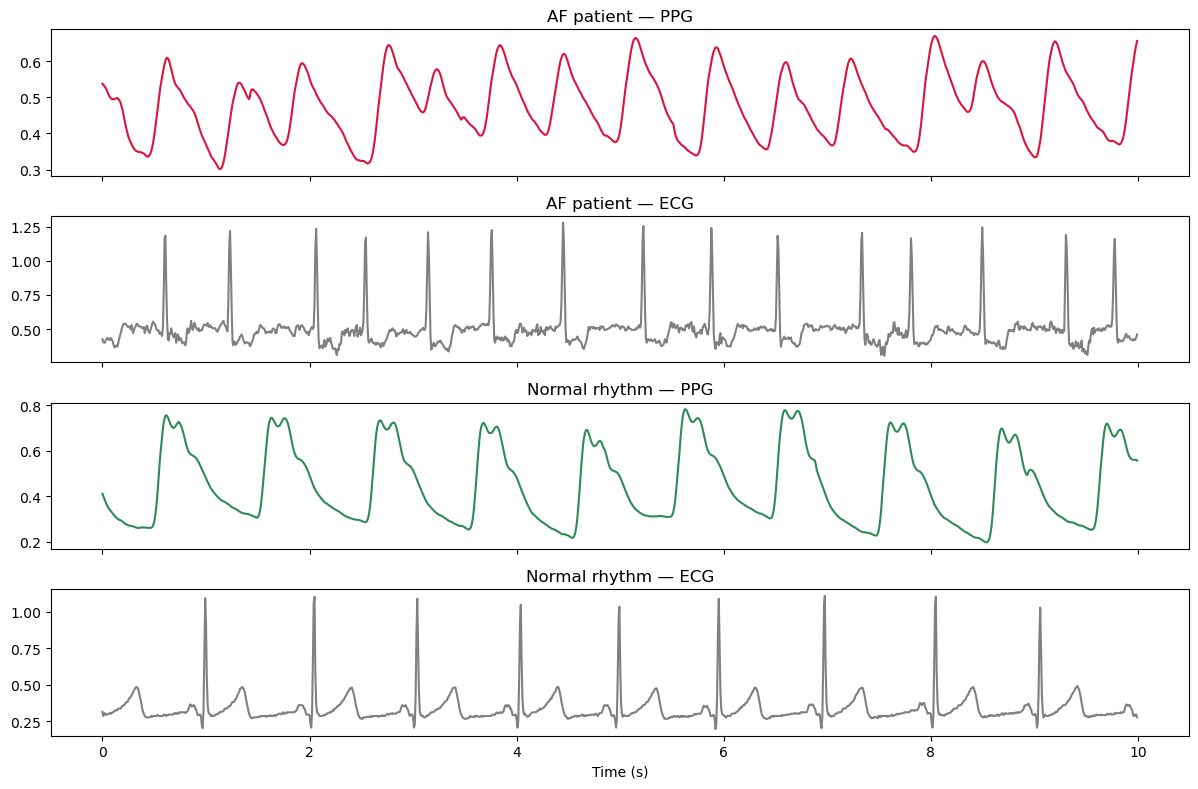

In [15]:
import matplotlib.pyplot as plt

fs = 125
seconds = 10
n = fs * seconds

af = pd.read_csv(af_files[0])
normal = pd.read_csv(non_af_files[0])

fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
t = af["Time"][:n] - af["Time"][0]

axes[0].plot(t, af["PPG"][:n], color="crimson")
axes[0].set_title("AF patient — PPG")
axes[1].plot(t, af["ECG"][:n], color="gray")
axes[1].set_title("AF patient — ECG")
axes[2].plot(t, normal["PPG"][:n], color="seagreen")
axes[2].set_title("Normal rhythm — PPG")
axes[3].plot(t, normal["ECG"][:n], color="gray")
axes[3].set_title("Normal rhythm — ECG")
axes[3].set_xlabel("Time (s)")

plt.tight_layout()
plt.show()

## Step 3: From beats to beat intervals

The classifier does not look at raw waveforms. It looks at the **time between consecutive beats** (inter-beat intervals, IBIs).

Beats are detected as signal peaks, with a minimum spacing of 0.33 s (a maximum of 180 bpm). The same detection runs on both ECG and PPG:

- **ECG** R-peaks are sharp and serve as the reference for when each beat really happened.
- **PPG** peaks are what the MAX30102 will provide on the device.

A normal rhythm gives a nearly flat interval line. AF gives an interval line that jumps up and down. How closely the PPG intervals follow the ECG intervals shows how well PPG captures beat timing.

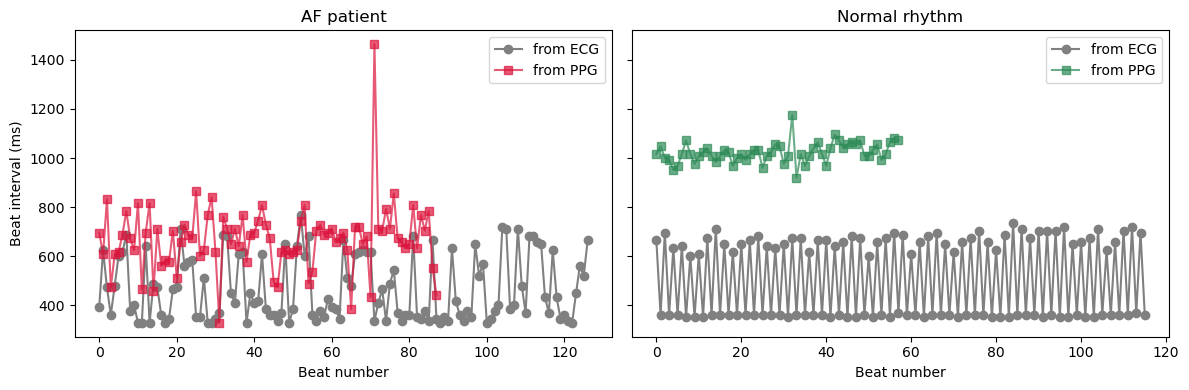

In [16]:
from scipy.signal import find_peaks
import numpy as np

def beat_intervals(signal, fs=125, height_pct=60):
    x = np.asarray(signal, dtype=float)
    peaks, _ = find_peaks(x, distance=int(0.33 * fs),
                          height=np.percentile(x, height_pct))
    return np.diff(peaks) / fs * 1000   # ms

n = 125 * 60   # 60 seconds
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, data, name, color in [(axes[0], af, "AF patient", "crimson"),
                              (axes[1], normal, "Normal rhythm", "seagreen")]:
    ibi_ecg = beat_intervals(data["ECG"][:n])
    ibi_ppg = beat_intervals(data["PPG"][:n])
    ax.plot(ibi_ecg, "o-", color="gray", label="from ECG")
    ax.plot(ibi_ppg, "s-", color=color, alpha=0.7, label="from PPG")
    ax.set_title(name)
    ax.set_xlabel("Beat number")
    ax.legend()

axes[0].set_ylabel("Beat interval (ms)")
plt.tight_layout()
plt.show()

## Step 4: Prepare the signal like the device will

The model must see the same kind of signal in training as it will on the microcontroller, so the dataset is processed to match the MAX30102 setup:

1. **Resample 125 Hz → 100 Hz.** The MAX30102 cannot sample at 125 Hz, so training data is converted to the device's rate.
2. **Band-pass filter 0.5–8 Hz.** This removes slow baseline drift (breathing, finger pressure) and high-frequency noise, keeping the pulse. The filter is *causal* (it uses only past samples), so the microcontroller can apply exactly the same filter in real time.
3. **Cut into 30-second windows.** Each window is one input to the classifier. The first 2 seconds are dropped while the filter settles.
4. **Normalize each window** (zero mean, unit standard deviation), so differences in signal strength between sensors don't matter.

39 windows of 30 s from one 20-minute recording


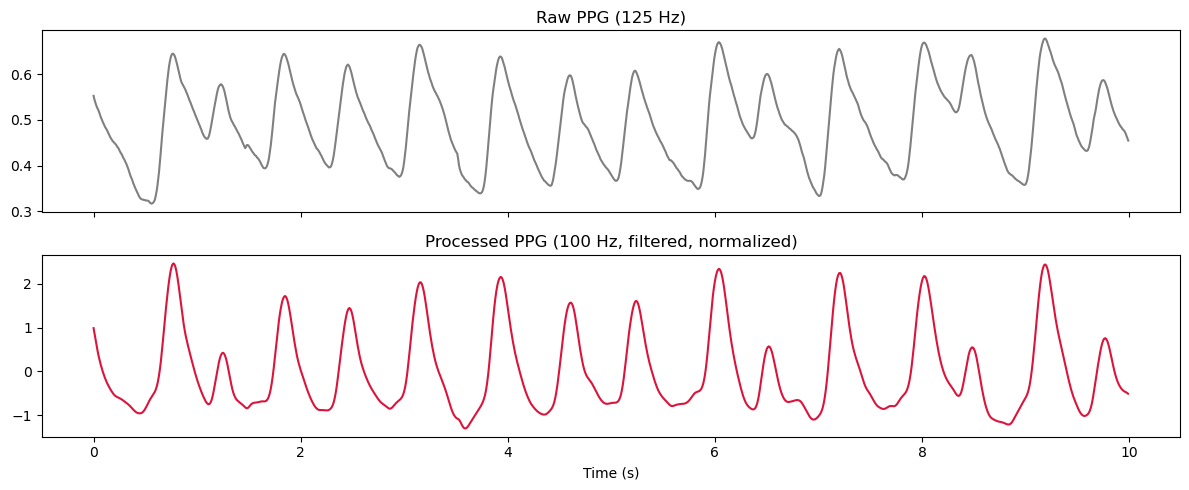

In [17]:
from scipy.signal import butter, sosfilt, resample_poly

FS_IN, FS_OUT = 125, 100
WIN_SEC = 30
BAND = (0.5, 8.0)

def preprocess(ppg_raw):
    x = pd.Series(np.asarray(ppg_raw, dtype=float)).interpolate(limit=10).to_numpy()
    x = resample_poly(x, FS_OUT, FS_IN)                      # 125 -> 100 Hz
    sos = butter(2, BAND, btype="bandpass", fs=FS_OUT, output="sos")
    return sosfilt(sos, x)                                   # causal filter

def make_windows(x, fs=FS_OUT, win_sec=WIN_SEC, skip_sec=2):
    win, skip = win_sec * fs, skip_sec * fs
    windows = []
    for start in range(skip, len(x) - win + 1, win):
        w = x[start:start + win]
        if np.isnan(w).any() or w.std() < 1e-6:              # gaps / flat signal
            continue
        windows.append((w - w.mean()) / w.std())
    return np.array(windows)

# Try it on one AF recording
clean = preprocess(af["PPG"])
windows = make_windows(clean)
print(f"{len(windows)} windows of {WIN_SEC} s from one 20-minute recording")

# Before vs. after, first 10 s of window 0
n_raw, n_new = FS_IN * 10, FS_OUT * 10
raw_seg = af["PPG"][2 * FS_IN : 2 * FS_IN + n_raw].to_numpy()

fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
axes[0].plot(np.arange(n_raw) / FS_IN, raw_seg, color="gray")
axes[0].set_title("Raw PPG (125 Hz)")
axes[1].plot(np.arange(n_new) / FS_OUT, windows[0][:n_new], color="crimson")
axes[1].set_title("Processed PPG (100 Hz, filtered, normalized)")
axes[1].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()

## Step 5: Detect beats and validate against ECG

Beats are found as peaks in the processed PPG window. A minimum spacing of 0.33 s (180 bpm max) prevents one pulse from being counted twice, and a minimum prominence rejects small ripples while still catching the weak beats that follow short intervals in AF.

To check the detector, the same 30-second window of ECG is processed and its R-peaks are detected. The ECG is the reference for when each heartbeat really happened.

The pulse reaches the finger about 0.2–0.3 s after the ECG spike, so beat *times* differ between the two signals. Beat *intervals* should match, and they are what the classifier uses.

Beats found — PPG: 45, ECG: 46
Beat counts differ, so intervals can't be compared one-to-one


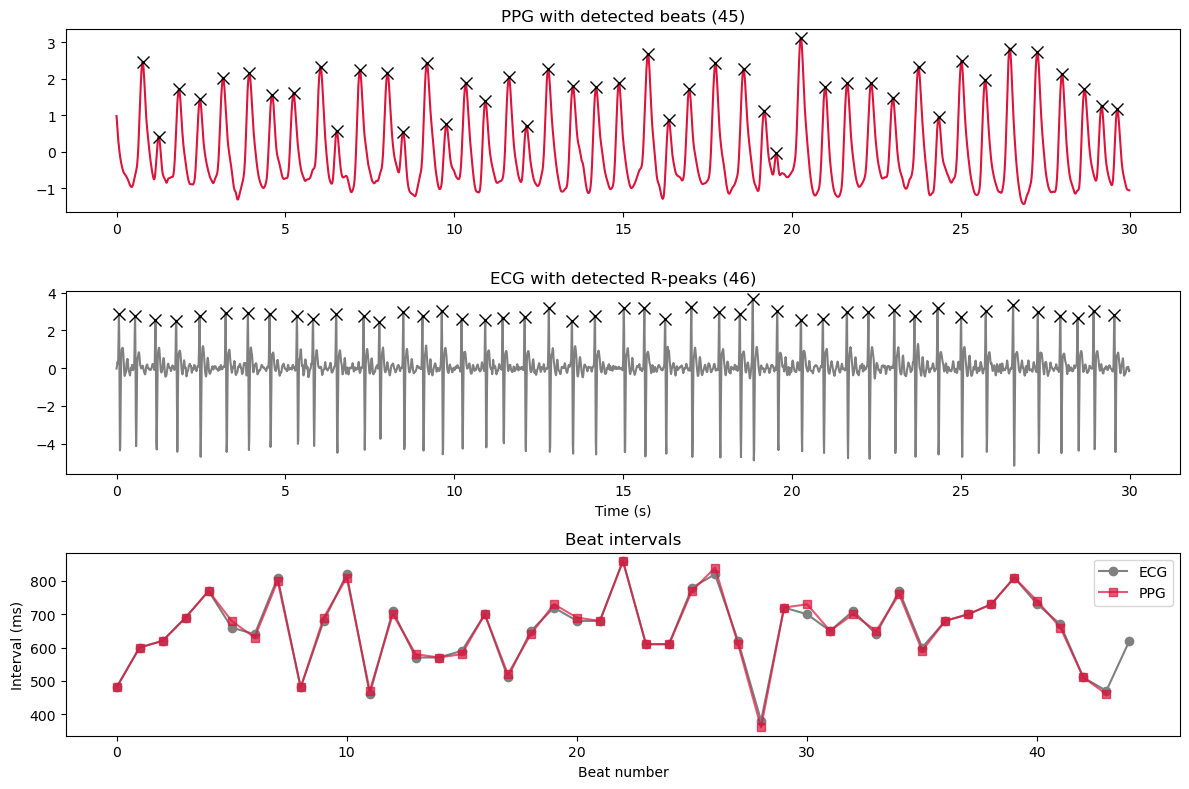

In [18]:
def detect_ppg_beats(w, fs=FS_OUT):
    peaks, _ = find_peaks(w, distance=int(0.33 * fs), prominence=0.5)
    return peaks

def detect_ecg_beats(ecg_raw, fs=FS_OUT):
    x = pd.Series(np.asarray(ecg_raw, dtype=float)).interpolate(limit=10).to_numpy()
    x = resample_poly(x, FS_OUT, FS_IN)
    sos = butter(2, (5, 20), btype="bandpass", fs=fs, output="sos")
    x = sosfilt(sos, x)
    return x

# Same window from PPG and ECG
i = 0
win, skip = WIN_SEC * FS_OUT, 2 * FS_OUT
start = skip + i * win

ppg_w = windows[i]
ecg_full = detect_ecg_beats(af["ECG"])
ecg_w = ecg_full[start:start + win]
ecg_w = (ecg_w - ecg_w.mean()) / ecg_w.std()

ppg_peaks = detect_ppg_beats(ppg_w)
ecg_peaks, _ = find_peaks(ecg_w, distance=int(0.33 * FS_OUT), prominence=2)

ppg_ibi = np.diff(ppg_peaks) / FS_OUT * 1000
ecg_ibi = np.diff(ecg_peaks) / FS_OUT * 1000

print(f"Beats found — PPG: {len(ppg_peaks)}, ECG: {len(ecg_peaks)}")
if len(ppg_ibi) == len(ecg_ibi):
    err = np.abs(ppg_ibi - ecg_ibi)
    print(f"Interval error — mean {err.mean():.1f} ms, max {err.max():.1f} ms")
else:
    print("Beat counts differ, so intervals can't be compared one-to-one")

# Plot
t = np.arange(win) / FS_OUT
fig, axes = plt.subplots(3, 1, figsize=(12, 8))
axes[0].plot(t, ppg_w, color="crimson")
axes[0].plot(t[ppg_peaks], ppg_w[ppg_peaks], "kx", ms=8)
axes[0].set_title(f"PPG with detected beats ({len(ppg_peaks)})")
axes[1].plot(t, ecg_w, color="gray")
axes[1].plot(t[ecg_peaks], ecg_w[ecg_peaks], "kx", ms=8)
axes[1].set_title(f"ECG with detected R-peaks ({len(ecg_peaks)})")
axes[1].set_xlabel("Time (s)")
axes[2].plot(ecg_ibi, "o-", color="gray", label="ECG")
axes[2].plot(ppg_ibi, "s-", color="crimson", alpha=0.7, label="PPG")
axes[2].set_title("Beat intervals")
axes[2].set_xlabel("Beat number")
axes[2].set_ylabel("Interval (ms)")
axes[2].legend()
plt.tight_layout()
plt.show()

## Step 6: Extract rhythm features from all patients

Every 30-second window from all 35 patients is processed with the pipeline from Steps 4–5, and eight features are computed from its beat intervals:

| Feature | Meaning |
|---|---|
| `mean_ibi_ms` | Average time between beats |
| `hr_bpm` | Heart rate |
| `sdnn` | Standard deviation of intervals (overall variability) |
| `rmssd` | Root mean square of successive differences (beat-to-beat variability) |
| `nrmssd` | RMSSD divided by mean interval (variability independent of heart rate) |
| `cv` | Coefficient of variation: SDNN divided by mean interval |
| `pnn50` | Fraction of successive intervals that differ by more than 50 ms |
| `median_abs_diff` | Median beat-to-beat change in interval |

Windows with fewer than 15 detected beats are rejected as unreliable. Each window keeps its patient ID, so later the data can be split by patient rather than by window. This prevents the model from being tested on patients it has already seen.

mimic_perform_af_001: 39/39 windows kept
mimic_perform_af_002: 39/39 windows kept
mimic_perform_af_003: 39/39 windows kept
mimic_perform_af_004: 39/39 windows kept
mimic_perform_af_005: 10/10 windows kept
mimic_perform_af_006: 15/15 windows kept
mimic_perform_af_007: 0/0 windows kept
mimic_perform_af_008: 39/39 windows kept
mimic_perform_af_009: 39/39 windows kept
mimic_perform_af_010: 39/39 windows kept
mimic_perform_af_011: 39/39 windows kept
mimic_perform_af_012: 39/39 windows kept
mimic_perform_af_013: 39/39 windows kept
mimic_perform_af_014: 39/39 windows kept
mimic_perform_af_015: 39/39 windows kept
mimic_perform_af_016: 39/39 windows kept
mimic_perform_af_017: 39/39 windows kept
mimic_perform_af_018: 39/39 windows kept
mimic_perform_af_019: 39/39 windows kept
mimic_perform_non_af_001: 39/39 windows kept
mimic_perform_non_af_002: 39/39 windows kept
mimic_perform_non_af_003: 39/39 windows kept
mimic_perform_non_af_004: 39/39 windows kept
mimic_perform_non_af_005: 39/39 windows kep

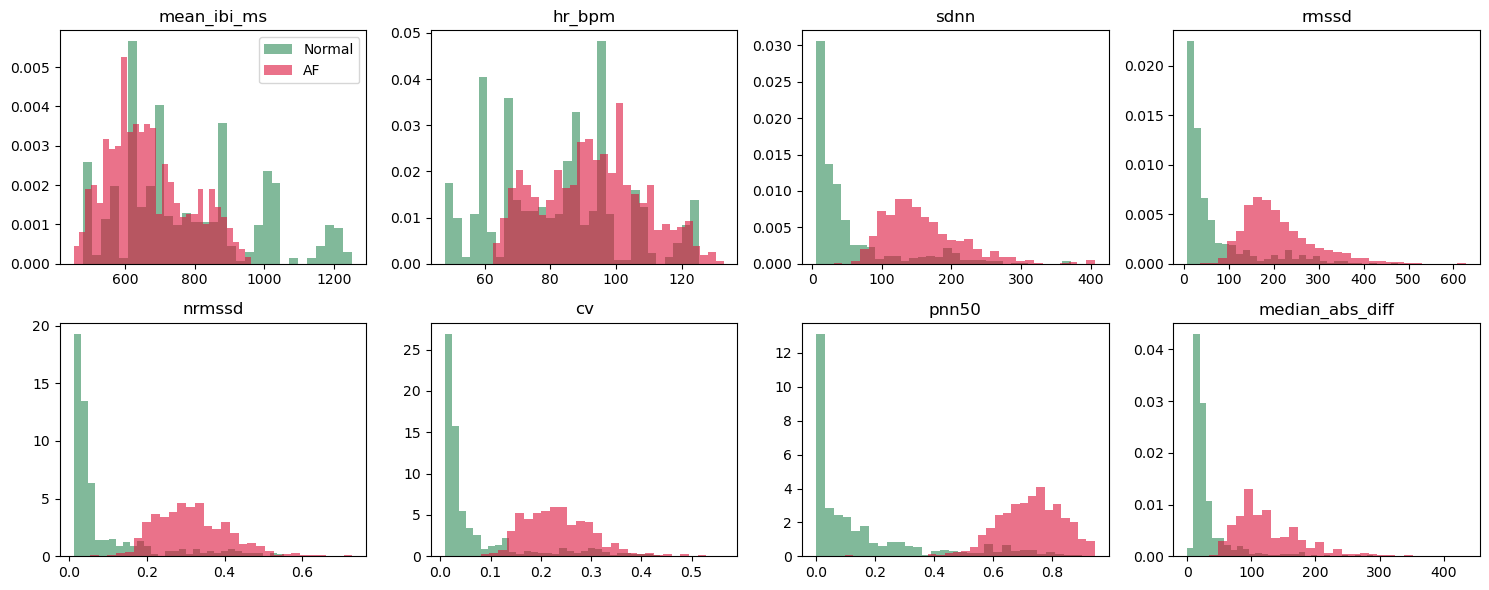

In [19]:
FEATURE_NAMES = ["mean_ibi_ms", "hr_bpm", "sdnn", "rmssd",
                 "nrmssd", "cv", "pnn50", "median_abs_diff"]
MIN_BEATS = 15

def ibi_features(w, fs=FS_OUT):
    peaks = detect_ppg_beats(w, fs)
    if len(peaks) < MIN_BEATS:
        return None
    ibi = np.diff(peaks) / fs * 1000
    ibi = ibi[(ibi > 300) & (ibi < 2000)]          # 30–200 bpm
    if len(ibi) < MIN_BEATS - 1:
        return None
    d = np.diff(ibi)
    mean_ibi = ibi.mean()
    rmssd = np.sqrt(np.mean(d ** 2))
    return [mean_ibi, 60000 / mean_ibi, ibi.std(), rmssd,
            rmssd / mean_ibi, ibi.std() / mean_ibi,
            np.mean(np.abs(d) > 50), np.median(np.abs(d))]

rows = []
for files, label in [(af_files, 1), (non_af_files, 0)]:
    for f in files:
        patient = os.path.basename(f).replace("_data.csv", "")
        ppg = pd.read_csv(f, usecols=["PPG"])["PPG"]
        wins = make_windows(preprocess(ppg))
        kept = 0
        for w in wins:
            feats = ibi_features(w)
            if feats is not None:
                rows.append([patient, label] + feats)
                kept += 1
        print(f"{patient}: {kept}/{len(wins)} windows kept")

data = pd.DataFrame(rows, columns=["patient", "label"] + FEATURE_NAMES)
data.to_csv("data/features.csv", index=False)
print(f"\n{len(data)} windows from {data['patient'].nunique()} patients "
      f"— AF: {(data.label == 1).sum()}, normal: {(data.label == 0).sum()}")

# Compare AF vs. normal for each feature
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, feat in zip(axes.flat, FEATURE_NAMES):
    ax.hist(data.loc[data.label == 0, feat], bins=30, alpha=0.6,
            color="seagreen", label="Normal", density=True)
    ax.hist(data.loc[data.label == 1, feat], bins=30, alpha=0.6,
            color="crimson", label="AF", density=True)
    ax.set_title(feat)
axes[0, 0].legend()
plt.tight_layout()
plt.show()

## Step 7: Train a classifier with patient-wise cross-validation

Heart rate (`hr_bpm`, `mean_ibi_ms`) overlaps heavily between groups, so it is left out. The model uses only rhythm-irregularity features, which are normalized by heart rate where possible: `nrmssd`, `cv`, `pnn50` and `median_abs_diff`.

**Model:** logistic regression. It is small enough to run on any microcontroller (one multiply-add per feature) and easy to interpret.

**Evaluation:** with only 35 patients, a single train/test split would be unreliable. Instead, **5-fold cross-validation grouped by patient** is used: each fold holds out about 7 patients the model never saw during training, and every patient is tested exactly once. Splitting by window instead would let the model see other windows from the same patient during training and inflate the results.

**Metrics:**
- **Sensitivity:** fraction of AF windows correctly flagged
- **Specificity:** fraction of normal windows correctly left alone (1 − false alarm rate)
- **AUC:** overall ability to rank AF above normal, from 0.5 (chance) to 1.0 (perfect)

A one-feature threshold on `nrmssd` is included as a baseline, to show what the model adds.

In [20]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, confusion_matrix

FEATURES = ["nrmssd", "cv", "pnn50", "median_abs_diff"]
X = data[FEATURES].to_numpy()
y = data["label"].to_numpy()
groups = data["patient"].to_numpy()

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
prob = np.zeros(len(y))           # out-of-fold predictions

for train_idx, test_idx in cv.split(X, y, groups):
    model = make_pipeline(StandardScaler(), LogisticRegression())
    model.fit(X[train_idx], y[train_idx])
    prob[test_idx] = model.predict_proba(X[test_idx])[:, 1]

def report(name, y_true, y_pred, score):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    print(f"{name:22s} sensitivity {tp/(tp+fn):.3f}  "
          f"specificity {tn/(tn+fp):.3f}  AUC {roc_auc_score(y_true, score):.3f}  "
          f"(false alarms: {fp} of {tn+fp} normal windows)")

print("Per-window results, patients never seen in training:\n")
report("Logistic regression", y, (prob >= 0.5).astype(int), prob)
report("nrmssd threshold 0.1", y, (data["nrmssd"] >= 0.1).astype(int), data["nrmssd"])

# Which normal-rhythm patients cause the false alarms?
data["prob_af"] = prob
fa = data[(data.label == 0) & (data.prob_af >= 0.5)]
print("\nFalse alarms by patient:")
print(fa.groupby("patient").size().sort_values(ascending=False))

Per-window results, patients never seen in training:

Logistic regression    sensitivity 0.985  specificity 0.852  AUC 0.908  (false alarms: 75 of 508 normal windows)
nrmssd threshold 0.1   sensitivity 0.998  specificity 0.758  AUC 0.913  (false alarms: 123 of 508 normal windows)

False alarms by patient:
patient
mimic_perform_non_af_014    39
mimic_perform_non_af_002    23
mimic_perform_non_af_009     6
mimic_perform_non_af_007     4
mimic_perform_non_af_001     1
mimic_perform_non_af_010     1
mimic_perform_non_af_012     1
dtype: int64


## Step 8: Investigate the false alarms

The baseline reaches sensitivity 0.985 and specificity 0.852 on unseen patients. Most false alarms (62 of 75) come from just two normal-rhythm patients (014 and 002).

Two explanations are possible:

1. **True rhythm irregularity:** "non-AF" means *not AF*, not necessarily a perfectly regular rhythm. ICU patients may have frequent ectopic (extra) beats. The ECG would then also look irregular.
2. **PPG signal problems:** the heart rhythm is regular, but noise or poor sensor contact makes PPG beats look irregular. The ECG would then look regular.

For every window of these patients, irregularity (`nrmssd`) is computed separately from PPG beats and from ECG beats. If both are high, the rhythm really is irregular. If only PPG is high, the signal is the problem, which is the case a signal-quality gate is designed to catch.

mimic_perform_non_af_014: windows above threshold — PPG 39, ECG 6 (of 39)
mimic_perform_non_af_002: windows above threshold — PPG 0, ECG 0 (of 39)


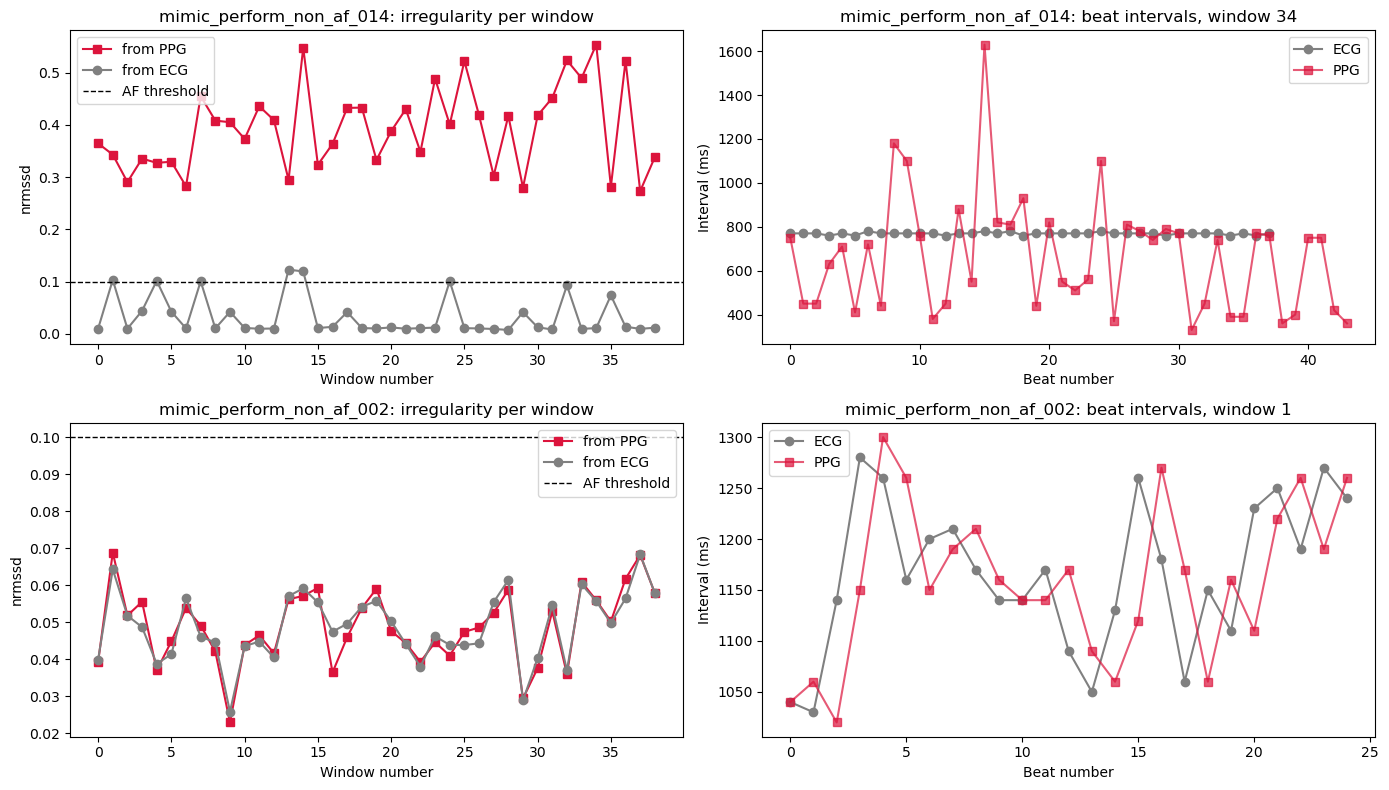

In [21]:
def ecg_clean(ecg_raw):
    x = pd.Series(np.asarray(ecg_raw, dtype=float)).interpolate(limit=10).to_numpy()
    x = resample_poly(x, FS_OUT, FS_IN)
    sos = butter(2, (5, 20), btype="bandpass", fs=FS_OUT, output="sos")
    return sosfilt(sos, x)

def nrmssd_from_peaks(peaks, fs=FS_OUT):
    ibi = np.diff(peaks) / fs * 1000
    ibi = ibi[(ibi > 300) & (ibi < 2000)]
    if len(ibi) < 10:
        return np.nan, ibi
    return np.sqrt(np.mean(np.diff(ibi) ** 2)) / ibi.mean(), ibi

def compare_patient(pid):
    f = [p for p in non_af_files if pid in p][0]
    d = pd.read_csv(f)
    ppg, ecg = preprocess(d["PPG"]), ecg_clean(d["ECG"])
    win, skip = WIN_SEC * FS_OUT, 2 * FS_OUT
    results = []
    for start in range(skip, len(ppg) - win + 1, win):
        p, e = ppg[start:start + win], ecg[start:start + win]
        if np.isnan(p).any() or p.std() < 1e-6 or np.isnan(e).any() or e.std() < 1e-6:
            continue
        p, e = (p - p.mean()) / p.std(), (e - e.mean()) / e.std()
        ppg_n, ppg_ibi = nrmssd_from_peaks(detect_ppg_beats(p))
        ecg_n, ecg_ibi = nrmssd_from_peaks(find_peaks(e, distance=33, prominence=2)[0])
        results.append((ppg_n, ecg_n, ppg_ibi, ecg_ibi))
    return results

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for row, pid in enumerate(["mimic_perform_non_af_014", "mimic_perform_non_af_002"]):
    res = compare_patient(pid)
    ppg_n = np.array([r[0] for r in res])
    ecg_n = np.array([r[1] for r in res])

    # Left: irregularity per window, PPG vs ECG
    ax = axes[row, 0]
    ax.plot(ppg_n, "s-", color="crimson", label="from PPG")
    ax.plot(ecg_n, "o-", color="gray", label="from ECG")
    ax.axhline(0.1, ls="--", color="black", lw=1, label="AF threshold")
    ax.set_title(f"{pid}: irregularity per window")
    ax.set_xlabel("Window number")
    ax.set_ylabel("nrmssd")
    ax.legend()

    # Right: beat intervals in the most irregular PPG window
    worst = int(np.nanargmax(ppg_n))
    ax = axes[row, 1]
    ax.plot(res[worst][3], "o-", color="gray", label="ECG")
    ax.plot(res[worst][2], "s-", color="crimson", alpha=0.7, label="PPG")
    ax.set_title(f"{pid}: beat intervals, window {worst}")
    ax.set_xlabel("Beat number")
    ax.set_ylabel("Interval (ms)")
    ax.legend()

    print(f"{pid}: windows above threshold — PPG {np.nansum(ppg_n >= 0.1)}, "
          f"ECG {np.nansum(ecg_n >= 0.1)} (of {len(res)})")

plt.tight_layout()
plt.show()

## Step 9: Normalize all features by heart rate

Step 8 found two separate causes of false alarms:

- **Patient 014: poor PPG signal.** The ECG shows a perfectly regular rhythm (~770 ms intervals), but the PPG beat detector double-counts some beats (intervals near half of 770 ms) and misses others (near double). The rhythm looks irregular only because the signal is poor. This motivates a **signal-quality gate** (later step).
- **Patient 002: feature design.** PPG and ECG agree, and the rhythm is normal. But at a slow heart rate (~1,150 ms intervals), normal beat-to-beat variation exceeds 50 ms, so `pnn50` and `median_abs_diff`, both measured in absolute milliseconds, look like AF.

The fix for the second problem is to express every feature relative to the patient's own heart rate:

| New feature | Definition |
|---|---|
| `pnn_rel` | Fraction of successive intervals that differ by more than 6.5% of the mean interval (equivalent to 50 ms at ~90 bpm) |
| `mad_rel` | Median beat-to-beat change divided by the mean interval |

The model is then retrained with only heart-rate-normalized features: `nrmssd`, `cv`, `pnn_rel` and `mad_rel`.

In [22]:
FEATURE_NAMES = ["mean_ibi_ms", "hr_bpm", "sdnn", "rmssd", "nrmssd", "cv",
                 "pnn50", "median_abs_diff", "pnn_rel", "mad_rel"]

def ibi_features(w, fs=FS_OUT):
    peaks = detect_ppg_beats(w, fs)
    if len(peaks) < MIN_BEATS:
        return None
    ibi = np.diff(peaks) / fs * 1000
    ibi = ibi[(ibi > 300) & (ibi < 2000)]
    if len(ibi) < MIN_BEATS - 1:
        return None
    d = np.abs(np.diff(ibi))
    m = ibi.mean()
    rmssd = np.sqrt(np.mean(d ** 2))
    return [m, 60000 / m, ibi.std(), rmssd, rmssd / m, ibi.std() / m,
            np.mean(d > 50), np.median(d),
            np.mean(d > 0.065 * m), np.median(d) / m]

rows = []
for files, label in [(af_files, 1), (non_af_files, 0)]:
    for f in files:
        patient = os.path.basename(f).replace("_data.csv", "")
        wins = make_windows(preprocess(pd.read_csv(f, usecols=["PPG"])["PPG"]))
        for k, w in enumerate(wins):
            feats = ibi_features(w)
            if feats is not None:
                rows.append([patient, label, k] + feats)

data = pd.DataFrame(rows, columns=["patient", "label", "window"] + FEATURE_NAMES)
data.to_csv("data/features.csv", index=False)
print(f"{len(data)} windows from {data['patient'].nunique()} patients")

1157 windows from 32 patients


In [23]:
def evaluate(features, name):
    X = data[features].to_numpy()
    y, groups = data["label"].to_numpy(), data["patient"].to_numpy()
    prob = np.zeros(len(y))
    for tr, te in StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42).split(X, y, groups):
        m = make_pipeline(StandardScaler(), LogisticRegression()).fit(X[tr], y[tr])
        prob[te] = m.predict_proba(X[te])[:, 1]
    report(name, y, (prob >= 0.5).astype(int), prob)
    return prob

print("Patients never seen in training:\n")
evaluate(["nrmssd", "cv", "pnn50", "median_abs_diff"], "Old features")
prob = evaluate(["nrmssd", "cv", "pnn_rel", "mad_rel"], "Normalized features")

data["prob_af"] = prob
fa = data[(data.label == 0) & (data.prob_af >= 0.5)]
print(f"\nFalse alarms by patient ({len(fa)} total):")
print(fa.groupby("patient").size().sort_values(ascending=False))

Patients never seen in training:

Old features           sensitivity 0.985  specificity 0.852  AUC 0.908  (false alarms: 75 of 508 normal windows)
Normalized features    sensitivity 0.983  specificity 0.902  AUC 0.939  (false alarms: 50 of 508 normal windows)

False alarms by patient (50 total):
patient
mimic_perform_non_af_014    39
mimic_perform_non_af_007     4
mimic_perform_non_af_002     2
mimic_perform_non_af_009     2
mimic_perform_non_af_010     1
mimic_perform_non_af_012     1
mimic_perform_non_af_016     1
dtype: int64


## Step 10: Signal-quality gate

After normalizing features, 39 of the 50 remaining false alarms (78%) come from a single patient (014), whose regular heart rhythm is misread because of a poor PPG signal. The other 15 normal-rhythm patients produce only 11 false alarms.

A signal-quality index (SQI) is computed from the PPG alone, since the device has no ECG:

1. Detect beats in the window.
2. Cut out each beat, centered on its peak, with a width of one median beat interval.
3. Average all beats into a **template** pulse shape.
4. SQI = mean correlation of each beat with the template (1.0 = every pulse identical in shape).

When the detector double-counts or misses beats, the cut-out segments are misaligned and the SQI drops. Windows below an SQI threshold are reported as **"unreliable signal"** instead of being classified.

**Important check:** AF itself changes pulse heights and spacing, so the gate must not reject AF windows much more often than normal ones. Otherwise it would hide real AF.

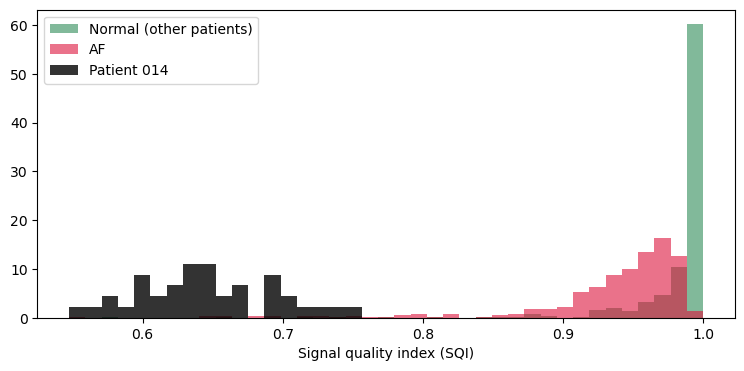

In [24]:
def template_sqi(w, fs=FS_OUT):
    peaks = detect_ppg_beats(w, fs)
    if len(peaks) < 5:
        return 0.0
    half = int(0.5 * np.median(np.diff(peaks)))
    beats = [w[p - half:p + half] for p in peaks
             if p - half >= 0 and p + half <= len(w)]
    if len(beats) < 5:
        return 0.0
    beats = np.array(beats)
    template = beats.mean(axis=0)
    return float(np.mean([np.corrcoef(b, template)[0, 1] for b in beats]))

sqi_lookup = {}
for files in (af_files, non_af_files):
    for f in files:
        patient = os.path.basename(f).replace("_data.csv", "")
        wins = make_windows(preprocess(pd.read_csv(f, usecols=["PPG"])["PPG"]))
        for k, w in enumerate(wins):
            sqi_lookup[(patient, k)] = template_sqi(w)

data["sqi"] = [sqi_lookup[(p, k)] for p, k in zip(data.patient, data.window)]

is_014 = data.patient == "mimic_perform_non_af_014"
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.linspace(data.sqi.min(), 1, 40)
ax.hist(data.sqi[(data.label == 0) & ~is_014], bins, alpha=0.6, color="seagreen", label="Normal (other patients)", density=True)
ax.hist(data.sqi[data.label == 1], bins, alpha=0.6, color="crimson", label="AF", density=True)
ax.hist(data.sqi[is_014], bins, alpha=0.8, color="black", label="Patient 014", density=True)
ax.set_xlabel("Signal quality index (SQI)")
ax.legend()
plt.show()

In [25]:
y = data.label.to_numpy()
pred = (data.prob_af >= 0.5).to_numpy()

print(f"{'SQI threshold':>13} | {'sensitivity':>11} {'specificity':>11} {'false alarms':>12} | "
      f"{'AF rejected':>11} {'normal rejected':>15}")
for t in [0.0, 0.80, 0.85, 0.90, 0.95]:
    keep = (data.sqi >= t).to_numpy()
    yk, pk = y[keep], pred[keep]
    tp, fn = ((pk == 1) & (yk == 1)).sum(), ((pk == 0) & (yk == 1)).sum()
    tn, fp = ((pk == 0) & (yk == 0)).sum(), ((pk == 1) & (yk == 0)).sum()
    af_rej = 1 - keep[y == 1].mean()
    nm_rej = 1 - keep[y == 0].mean()
    print(f"{t:>13.2f} | {tp/(tp+fn):>11.3f} {tn/(tn+fp):>11.3f} {fp:>12d} | "
          f"{af_rej:>11.1%} {nm_rej:>15.1%}")

SQI threshold | sensitivity specificity false alarms | AF rejected normal rejected
         0.00 |       0.983       0.902           50 |        0.0%            0.0%
         0.80 |       0.982       0.983            8 |        4.5%            8.7%
         0.85 |       0.982       0.985            7 |        5.7%            9.1%
         0.90 |       0.984       0.989            5 |       12.0%           10.6%
         0.95 |       0.992       0.988            5 |       45.1%           15.7%


### Results: effect of the quality gate

| SQI threshold | Sensitivity | Specificity | False alarms | AF windows rejected | Normal windows rejected |
|---|---|---|---|---|---|
| none | 0.983 | 0.902 | 50 | 0.0% | 0.0% |
| 0.80 | 0.982 | 0.983 | 8 | 4.5% | 8.7% |
| 0.85 | 0.982 | 0.985 | 7 | 5.7% | 9.1% |
| 0.90 | 0.984 | 0.989 | 5 | 12.0% | 10.6% |
| 0.95 | 0.992 | 0.988 | 5 | 45.1% | 15.7% |

At SQI ≥ 0.80, the gate **reduces false alarms by 84% (50 → 8)** and raises specificity from 0.902 to 0.983, with no loss of sensitivity, while rejecting 4.5% of AF windows.

**Limitation found:** AF windows naturally have lower template SQI, because irregular beats change pulse shape. Above about 0.85, the gate rejects AF windows at a rapidly increasing rate (45% at 0.95). A template-based quality index cannot fully distinguish a noisy signal from an irregular heart, which motivates a quality model designed to be AF-aware.

*These thresholds were explored on the full dataset; Step 11 selects the threshold inside cross-validation for an unbiased estimate.*

## Step 11: Unbiased evaluation of the quality gate

To avoid tuning the threshold on the patients it is tested on, the threshold is selected inside each cross-validation fold, using only that fold's training patients. The rule: choose the **highest** SQI threshold that rejects **no more than 5% of AF windows** in the training data. This protects sensitivity while removing as many poor-quality windows as possible. The classifier and the threshold are then both applied to the held-out patients.

In [26]:
FEATURES = ["nrmssd", "cv", "pnn_rel", "mad_rel"]
X = data[FEATURES].to_numpy()
y = data.label.to_numpy()
groups = data.patient.to_numpy()
sqi = data.sqi.to_numpy()

prob = np.zeros(len(y))
keep = np.zeros(len(y), dtype=bool)
chosen = []

for tr, te in StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42).split(X, y, groups):
    model = make_pipeline(StandardScaler(), LogisticRegression()).fit(X[tr], y[tr])
    prob[te] = model.predict_proba(X[te])[:, 1]

    af_sqi_train = sqi[tr][y[tr] == 1]
    t = np.quantile(af_sqi_train, 0.05)     # rejects ≤5% of training AF
    chosen.append(t)
    keep[te] = sqi[te] >= t

pred = prob >= 0.5
print("Thresholds chosen per fold:", np.round(chosen, 3))
print()
report("No gate", y, pred.astype(int), prob)
report("With quality gate", y[keep], pred[keep].astype(int), prob[keep])
print(f"\nRejected — AF: {1 - keep[y == 1].mean():.1%}, normal: {1 - keep[y == 0].mean():.1%}")

Thresholds chosen per fold: [0.794 0.877 0.838 0.798 0.794]

No gate                sensitivity 0.983  specificity 0.902  AUC 0.939  (false alarms: 50 of 508 normal windows)
With quality gate      sensitivity 0.982  specificity 0.983  AUC 0.998  (false alarms: 8 of 464 normal windows)

Rejected — AF: 5.4%, normal: 8.7%


## Step 11 results: unbiased evaluation

Thresholds selected inside each fold: 0.794, 0.877, 0.838, 0.798, 0.794. They are stable across folds, so the gate does not depend on a finely tuned value.

| | Sensitivity | Specificity | AUC | False alarms | AF rejected | Normal rejected |
|---|---|---|---|---|---|---|
| No gate | 0.983 | 0.902 | 0.939 | 50 / 508 | — | — |
| With quality gate | 0.982 | 0.983 | 0.998 | 8 / 464 | 5.4% | 8.7% |

On patients unseen during both training and threshold selection, the PPG-only quality gate **reduced false AF alarms by 84%** and raised specificity from 0.902 to 0.983, with no meaningful loss of sensitivity.

**Limitations:** much of the improvement comes from one normal-rhythm patient with poor PPG quality; the dataset contains 35 ICU patients with clinical fingertip sensors; results are per window, and windows from the same patient are correlated.

## Step 12: Tuned neural network vs. tuned logistic regression

Both models are tuned with a **nested grid search**:

- **Outer loop:** the same 5 patient-wise folds as before. Held-out patients are used only for the final evaluation.
- **Inner loop:** within each outer fold's training patients, a 3-fold patient-wise cross-validation scores every hyperparameter combination by AUC. The best combination is retrained on all training patients and then tested on the held-out patients.

Tuning on the test patients would inflate the results; nesting keeps them unbiased.

**Neural network grid** (12 combinations):

| Hyperparameter | Values |
|---|---|
| Units per hidden layer | 8, 16, 32 |
| Hidden layers | 1, 2 |
| Learning rate | 0.001, 0.01 |

Each network has a normalization layer, ReLU hidden layers and a sigmoid output, trained for 60 epochs with the Adam optimizer.

**Logistic regression grid:** regularization strength C = 0.01, 0.1, 1, 10, 100.

Both models use the same four heart-rate-normalized features and the same quality gate from Step 11.

In [27]:
import tensorflow as tf
from itertools import product
from sklearn.model_selection import GridSearchCV

tf.keras.utils.set_random_seed(42)
X32 = X.astype(np.float32)

def build_model(X_train, units, layers, lr):
    norm = tf.keras.layers.Normalization()
    norm.adapt(X_train)
    model = tf.keras.Sequential([tf.keras.Input(shape=(X_train.shape[1],)), norm])
    for _ in range(layers):
        model.add(tf.keras.layers.Dense(units, activation="relu"))
    model.add(tf.keras.layers.Dense(1, activation="sigmoid"))
    model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="binary_crossentropy")
    return model

def fit_predict(cfg, X_tr, y_tr, X_te):
    tf.keras.backend.clear_session()
    model = build_model(X_tr, **cfg)
    model.fit(X_tr, y_tr, epochs=60, batch_size=64, verbose=0)
    return model.predict(X_te, verbose=0).ravel(), model

GRID = {"units": [8, 16, 32], "layers": [1, 2], "lr": [1e-3, 1e-2]}
configs = [dict(zip(GRID, v)) for v in product(*GRID.values())]

outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
inner = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=0)

prob_nn = np.zeros(len(y))
prob_lr = np.zeros(len(y))

for fold, (tr, te) in enumerate(outer.split(X, y, groups)):
    # --- Neural network: manual grid search on training patients only ---
    scores = []
    for cfg in configs:
        aucs = []
        for itr, iva in inner.split(X32[tr], y[tr], groups[tr]):
            p, _ = fit_predict(cfg, X32[tr][itr], y[tr][itr], X32[tr][iva])
            aucs.append(roc_auc_score(y[tr][iva], p))
        scores.append(np.mean(aucs))
    best = configs[int(np.argmax(scores))]
    prob_nn[te], nn_model = fit_predict(best, X32[tr], y[tr], X32[te])

    # --- Logistic regression: GridSearchCV on training patients only ---
    lr_search = GridSearchCV(
        make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
        {"logisticregression__C": [0.01, 0.1, 1, 10, 100]},
        scoring="roc_auc", cv=inner)
    lr_search.fit(X[tr], y[tr], groups=groups[tr])
    prob_lr[te] = lr_search.predict_proba(X[te])[:, 1]

    print(f"Fold {fold + 1}: NN best {best} (inner AUC {max(scores):.3f}) | "
          f"LogReg best C={lr_search.best_params_['logisticregression__C']}")

print(f"\nLast NN size: {nn_model.count_params()} parameters\n")
print("Patients never seen in training or tuning:\n")
report("LogReg, no gate", y, (prob_lr >= 0.5).astype(int), prob_lr)
report("NN, no gate", y, (prob_nn >= 0.5).astype(int), prob_nn)
report("LogReg + gate", y[keep], (prob_lr[keep] >= 0.5).astype(int), prob_lr[keep])
report("NN + gate", y[keep], (prob_nn[keep] >= 0.5).astype(int), prob_nn[keep])

Fold 1: NN best {'units': 8, 'layers': 1, 'lr': 0.01} (inner AUC 0.997) | LogReg best C=1
Fold 2: NN best {'units': 16, 'layers': 1, 'lr': 0.01} (inner AUC 0.991) | LogReg best C=100
Fold 3: NN best {'units': 16, 'layers': 2, 'lr': 0.01} (inner AUC 0.975) | LogReg best C=10
Fold 4: NN best {'units': 32, 'layers': 1, 'lr': 0.01} (inner AUC 0.989) | LogReg best C=100
Fold 5: NN best {'units': 16, 'layers': 1, 'lr': 0.01} (inner AUC 0.961) | LogReg best C=100

Last NN size: 106 parameters

Patients never seen in training or tuning:

LogReg, no gate        sensitivity 0.975  specificity 0.902  AUC 0.942  (false alarms: 50 of 508 normal windows)
NN, no gate            sensitivity 0.980  specificity 0.904  AUC 0.955  (false alarms: 49 of 508 normal windows)
LogReg + gate          sensitivity 0.979  specificity 0.983  AUC 0.997  (false alarms: 8 of 464 normal windows)
NN + gate              sensitivity 0.984  specificity 0.987  AUC 0.997  (false alarms: 6 of 464 normal windows)


### Step 12 results

Best settings per fold (inner patient-wise CV, AUC):

| Fold | NN units | NN layers | NN learning rate | Inner AUC | LogReg C |
|---|---|---|---|---|---|
| 1 | 8 | 1 | 0.01 | 0.997 | 1 |
| 2 | 16 | 1 | 0.01 | 0.991 | 100 |
| 3 | 16 | 2 | 0.01 | 0.975 | 10 |
| 4 | 32 | 1 | 0.01 | 0.989 | 100 |
| 5 | 16 | 1 | 0.01 | 0.961 | 100 |

Results on patients unseen during training and tuning:

| Model | Sensitivity | Specificity | AUC | False alarms |
|---|---|---|---|---|
| Logistic regression | 0.975 | 0.902 | 0.942 | 50 / 508 |
| Neural network | 0.980 | 0.904 | 0.955 | 49 / 508 |
| Logistic regression + quality gate | 0.979 | 0.983 | 0.997 | 8 / 464 |
| **Neural network + quality gate** | **0.984** | **0.987** | **0.997** | **6 / 464** |

The tuned neural network performs on par with tuned logistic regression; the quality gate accounts for nearly all of the improvement (false alarms 49 → 6). A learning rate of 0.01 was chosen in every fold and one hidden layer in four of five, while the number of units had little effect. The deployed model uses **16 units, 1 hidden layer, learning rate 0.01** (106 parameters).

## Step 13: int8 quantization for the microcontroller

The model is converted to an 8-bit integer (int8) TensorFlow Lite model, which is smaller and runs faster on microcontrollers without floating-point hardware acceleration.

**Measuring the cost of quantization:** using the fixed configuration (16 units, 1 hidden layer, learning rate 0.01), each outer fold trains a float model, converts it to int8 using training data for calibration, and compares float and int8 predictions on the held-out patients.

**Final model:** trained on all 35 patients, converted to int8, and exported as:
- `af_model.tflite`: the TensorFlow Lite model
- `af_model.h`: the same model as a C array, to compile into the ESP32 firmware

The input and output quantization parameters (scale and zero point) are printed, because the firmware needs them to convert features to int8 and the output back to a probability.

In [28]:
BEST = {"units": 16, "layers": 1, "lr": 1e-2}

def to_int8(model, X_calib):
    try:
        converter = tf.lite.TFLiteConverter.from_keras_model(model)
    except Exception:
        model.export("tmp_saved_model")
        converter = tf.lite.TFLiteConverter.from_saved_model("tmp_saved_model")

    def representative_data():
        for i in range(len(X_calib)):
            yield [X_calib[i:i + 1]]

    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    converter.representative_dataset = representative_data
    converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    converter.inference_input_type = tf.int8
    converter.inference_output_type = tf.int8
    return converter.convert()

def run_int8(tflite_model, X_in):
    interp = tf.lite.Interpreter(model_content=tflite_model)
    interp.allocate_tensors()
    inp, out = interp.get_input_details()[0], interp.get_output_details()[0]
    s_in, z_in = inp["quantization"]
    s_out, z_out = out["quantization"]
    probs = []
    for x in X_in:
        q = np.clip(np.round(x / s_in + z_in), -128, 127).astype(np.int8)
        interp.set_tensor(inp["index"], q[None, :])
        interp.invoke()
        probs.append((interp.get_tensor(out["index"])[0, 0].astype(np.float32) - z_out) * s_out)
    return np.array(probs)

# --- Cost of quantization on held-out patients ---
prob_float = np.zeros(len(y))
prob_int8 = np.zeros(len(y))
for fold, (tr, te) in enumerate(outer.split(X, y, groups)):
    p, model = fit_predict(BEST, X32[tr], y[tr], X32[te])
    prob_float[te] = p
    prob_int8[te] = run_int8(to_int8(model, X32[tr]), X32[te])
    print(f"Fold {fold + 1} done")

agree = np.mean((prob_float >= 0.5) == (prob_int8 >= 0.5))
print(f"\nFloat and int8 give the same decision on {agree:.2%} of windows\n")
report("Float32 + gate", y[keep], (prob_float[keep] >= 0.5).astype(int), prob_float[keep])
report("Int8 + gate", y[keep], (prob_int8[keep] >= 0.5).astype(int), prob_int8[keep])

# --- Final model on all patients, exported for the ESP32 ---
_, final_model = fit_predict(BEST, X32, y, X32[:1])
tflite_final = to_int8(final_model, X32)

with open("af_model.tflite", "wb") as f:
    f.write(tflite_final)

with open("af_model.h", "w") as f:
    f.write("// AF classifier, int8 TensorFlow Lite model\n")
    f.write("// Inputs (in order): nrmssd, cv, pnn_rel, mad_rel\n")
    f.write("#pragma once\n\n")
    f.write(f"const unsigned int af_model_len = {len(tflite_final)};\n")
    f.write("alignas(16) const unsigned char af_model[] = {\n")
    for i in range(0, len(tflite_final), 12):
        f.write("  " + ", ".join(f"0x{b:02x}" for b in tflite_final[i:i + 12]) + ",\n")
    f.write("};\n")

interp = tf.lite.Interpreter(model_content=tflite_final)
inp, out = interp.get_input_details()[0], interp.get_output_details()[0]
print(f"\nSaved af_model.tflite and af_model.h ({len(tflite_final)} bytes)")
print(f"Input  quantization: scale={inp['quantization'][0]:.6f}, zero_point={inp['quantization'][1]}")
print(f"Output quantization: scale={out['quantization'][0]:.6f}, zero_point={out['quantization'][1]}")

INFO:tensorflow:Assets written to: C:\Users\HP\AppData\Local\Temp\tmprwhwo7ir\assets


INFO:tensorflow:Assets written to: C:\Users\HP\AppData\Local\Temp\tmprwhwo7ir\assets
c:\Users\HP\miniconda3.2\envs\py310-gpu\lib\site-packages\tensorflow\lite\python\convert.py:766: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn("Statistics for quantized inputs were expected, but not "


Fold 1 done
INFO:tensorflow:Assets written to: C:\Users\HP\AppData\Local\Temp\tmpz01cn1tq\assets


INFO:tensorflow:Assets written to: C:\Users\HP\AppData\Local\Temp\tmpz01cn1tq\assets
c:\Users\HP\miniconda3.2\envs\py310-gpu\lib\site-packages\tensorflow\lite\python\convert.py:766: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn("Statistics for quantized inputs were expected, but not "


Fold 2 done
INFO:tensorflow:Assets written to: C:\Users\HP\AppData\Local\Temp\tmph730aj9a\assets


INFO:tensorflow:Assets written to: C:\Users\HP\AppData\Local\Temp\tmph730aj9a\assets
c:\Users\HP\miniconda3.2\envs\py310-gpu\lib\site-packages\tensorflow\lite\python\convert.py:766: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn("Statistics for quantized inputs were expected, but not "


... (4 outputs left out)

Fold 5 done

Float and int8 give the same decision on 99.91% of windows

Float32 + gate         sensitivity 0.985  specificity 0.985  AUC 0.997  (false alarms: 7 of 464 normal windows)
Int8 + gate            sensitivity 0.985  specificity 0.985  AUC 0.998  (false alarms: 7 of 464 normal windows)
INFO:tensorflow:Assets written to: C:\Users\HP\AppData\Local\Temp\tmp1advci4a\assets


INFO:tensorflow:Assets written to: C:\Users\HP\AppData\Local\Temp\tmp1advci4a\assets



Saved af_model.tflite and af_model.h (2848 bytes)
Input  quantization: scale=0.003836, zero_point=-128
Output quantization: scale=0.003906, zero_point=-128


c:\Users\HP\miniconda3.2\envs\py310-gpu\lib\site-packages\tensorflow\lite\python\convert.py:766: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn("Statistics for quantized inputs were expected, but not "


### Step 13 results (corrected calibration)

Calibrating int8 quantization on all training windows from both classes:

| Model | Sensitivity | Specificity | AUC | False alarms |
|---|---|---|---|---|
| Float32 + quality gate | 0.985 | 0.985 | 0.997 | 7 / 464 |
| **Int8 + quality gate** | **0.985** | **0.985** | **0.998** | **7 / 464** |

Float and int8 models give the same decision on **99.91%** of held-out windows. Quantization causes no measurable loss of accuracy.

**Exported model:** 2,848 bytes. Input scale 0.003836, zero point −128; output scale 1/256, zero point −128.
| Tensor | Scale | Zero point | Meaning |
|---|---|---|---|
| Input | 0.003795 | −128 | int8 = round(feature / 0.003795) − 128, clipped to [−128, 127]; covers feature values 0 to ~0.97 |
| Output | 0.003906 (1/256) | −128 | probability = (int8 + 128) / 256; AF if int8 ≥ 0 |

All four input features are ratios on similar scales (0 to ~1), so a single input scale represents them well.

## Step 14: Export the model and golden test vectors for the firmware

The int8 model is written as a C array (`af_model.h`). A set of real feature vectors is written to `test_vectors.h`, along with the exact int8 output that TensorFlow Lite's reference kernels give for each. The firmware runs the same inputs on the microcontroller and checks that it gets the same outputs, which proves the model was deployed correctly.

The test set holds 8 random windows per class plus the 4 windows closest to the decision boundary, where small rounding differences between PC and microcontroller would show up first.

In [29]:
import numpy as np
import pandas as pd
import tensorflow as tf
from pathlib import Path

# --- Load what earlier steps saved to disk ---
tflite_final = Path("af_model.tflite").read_bytes()
data = pd.read_csv("data/features.csv")
FEATURES = ["nrmssd", "cv", "pnn_rel", "mad_rel"]
X32 = data[FEATURES].to_numpy(dtype=np.float32)
y = data["label"].to_numpy()

FW_SRC = Path("af_firmware/src")
FW_SRC.mkdir(parents=True, exist_ok=True)
N_PER_CLASS = 8

def c_array(name, data_bytes):
    lines = [f"alignas(16) const unsigned char {name}[] = {{"]
    for i in range(0, len(data_bytes), 12):
        lines.append("  " + ", ".join(f"0x{b:02x}" for b in data_bytes[i:i + 12]) + ",")
    lines.append("};")
    return "\n".join(lines)

# 1) Model as a C array
(FW_SRC / "af_model.h").write_text(
    "// AF classifier, int8 TensorFlow Lite model (generated by the notebook)\n"
    "// Inputs (in order): nrmssd, cv, pnn_rel, mad_rel\n"
    "#pragma once\n\n"
    f"const unsigned int af_model_len = {len(tflite_final)};\n"
    + c_array("af_model", tflite_final) + "\n")

# 2) Golden vectors, using reference kernels (closest to TFLite Micro)
interp = tf.lite.Interpreter(
    model_content=tflite_final,
    experimental_op_resolver_type=tf.lite.experimental.OpResolverType.BUILTIN_REF)
interp.allocate_tensors()
inp, out = interp.get_input_details()[0], interp.get_output_details()[0]
s_in, z_in = inp["quantization"]

def run_int8(x):
    q = np.clip(np.round(x / s_in + z_in), -128, 127).astype(np.int8)
    interp.set_tensor(inp["index"], q[None, :])
    interp.invoke()
    return int(interp.get_tensor(out["index"])[0, 0])

all_out = np.array([run_int8(x) for x in X32])
rng = np.random.default_rng(0)
idx = np.concatenate([rng.choice(np.where(y == c)[0], N_PER_CLASS, replace=False)
                      for c in (0, 1)] + [np.argsort(np.abs(all_out))[:4]])
expected = all_out[idx].tolist()

rows = ",\n".join("  {" + ", ".join(f"{v:.7f}f" for v in X32[i]) + "}" for i in idx)
(FW_SRC / "test_vectors.h").write_text(
    "// Golden test vectors (generated by the notebook)\n"
    "#pragma once\n#include <stdint.h>\n\n"
    f"#define AF_NUM_TESTS {len(idx)}\n#define AF_NUM_FEATURES {X32.shape[1]}\n\n"
    f"static const float af_test_features[AF_NUM_TESTS][AF_NUM_FEATURES] = {{\n{rows}\n}};\n\n"
    "static const int8_t af_test_expected[AF_NUM_TESTS] = {"
    + ", ".join(map(str, expected)) + "};\n\n"
    "static const uint8_t af_test_label[AF_NUM_TESTS] = {"
    + ", ".join(str(int(y[i])) for i in idx) + "};\n")

ops = sorted({d["op_name"] for d in interp._get_ops_details()})
print("Model operations:", ops)
print(f"Input  scale {s_in:.6f}, zero point {z_in}")
print(f"Wrote {FW_SRC / 'af_model.h'} ({len(tflite_final)} bytes) and "
      f"{FW_SRC / 'test_vectors.h'} ({len(idx)} windows)")
print("Expected outputs:", expected)

Model operations: ['FULLY_CONNECTED', 'LOGISTIC', 'MUL', 'SUB']
Input  scale 0.003836, zero point -128
Wrote af_firmware\src\af_model.h (2848 bytes) and af_firmware\src\test_vectors.h (20 windows)
Expected outputs: [112, 15, -128, -128, -126, -122, -128, -128, 125, 123, 127, 127, 127, 127, 124, -30, 0, 5, 5, 5]


In [30]:
print("Unique outputs:", len(np.unique(all_out)), "of", len(all_out), "windows")
vals, counts = np.unique(all_out, return_counts=True)
print("Most common outputs:", sorted(zip(counts, vals), reverse=True)[:5])
print(f"Windows at exactly -29: normal {np.sum((all_out == -29) & (y == 0))}, "
      f"AF {np.sum((all_out == -29) & (y == 1))}")
print(f"Final model on all windows: accuracy {np.mean((all_out >= 0) == y):.3f}")

Unique outputs: 77 of 1157 windows
Most common outputs: [(369, -128), (241, 127), (53, 126), (35, -127), (30, 125)]
Windows at exactly -29: normal 0, AF 0
Final model on all windows: accuracy 0.959


## Step 15: On-device verification (Arduino Nano 33 BLE Sense, Zephyr RTOS)

The int8 model runs on the nRF52840 (Arm Cortex-M4F, 64 MHz) under Zephyr RTOS v4.4 with TensorFlow Lite Micro and CMSIS-NN kernels, without the Arduino framework.

The firmware runs 20 golden feature vectors exported from Python (8 normal, 8 AF, and the 4 windows nearest the decision boundary) and compares each int8 output with TensorFlow Lite's reference kernels on the PC.

| Metric | Result |
|---|---|
| Outputs identical to Python | 20 / 20 (including all 4 boundary windows) |
| Inference time | 299 µs |
| Tensor arena used | 1,028 bytes |
| Model size | 2,848 bytes |
| Firmware total | 114 KB flash, 26 KB RAM |

Build: `west build -b arduino_nano_33_ble/nrf52840/sense af_firmware -S cdc-acm-console`

## Step 16: Retrain the final model and check its health

The first final model (trained on all patients) had collapsed: for 466 of 1,157 windows, all hidden ReLU units were inactive, so the output was fixed at the bias value (p = 0.387). Decisions were still correct, but normal windows sat only 29 quantization steps from the threshold and probabilities below 0.387 were impossible.

The final model is retrained with 5 random seeds at each of two learning rates (0.01 from the grid search, and 0.001). For each run, the following are recorded:
- training loss
- **dead units:** hidden units that never activate on any window
- **plateau share:** the fraction of windows sharing the single most common output

The run with the lowest training loss among those without a collapse is kept, converted to int8, and re-exported to the firmware.

In [31]:
import tensorflow as tf

def build_model(X_train, units=16, layers=1, lr=1e-2):
    norm = tf.keras.layers.Normalization()
    norm.adapt(X_train)
    model = tf.keras.Sequential([tf.keras.Input(shape=(X_train.shape[1],)), norm])
    for _ in range(layers):
        model.add(tf.keras.layers.Dense(units, activation="relu"))
    model.add(tf.keras.layers.Dense(1, activation="sigmoid"))
    model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="binary_crossentropy")
    return model

def health(model):
    hidden = tf.keras.Model(model.inputs, model.layers[1].output)   # output of the Dense(16)
    act = hidden.predict(X32, verbose=0)
    dead = int(np.sum(act.max(axis=0) <= 0))
    p = model.predict(X32, verbose=0).ravel()
    _, counts = np.unique(np.round(p, 4), return_counts=True)
    loss = float(model.evaluate(X32, y, verbose=0))
    acc = float(np.mean((p >= 0.5) == y))
    return loss, dead, counts.max() / len(p), p.min(), acc

results = []
for lr in (1e-2, 1e-3):
    epochs = 60 if lr == 1e-2 else 200
    for seed in range(5):
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(seed)
        m = build_model(X32, lr=lr)
        m.fit(X32, y, epochs=epochs, batch_size=64, verbose=0)
        loss, dead, plateau, pmin, acc = health(m)
        results.append(dict(lr=lr, seed=seed, loss=loss, dead=dead,
                            plateau=plateau, p_min=pmin, acc=acc, model=m))
        print(f"lr {lr:<6} seed {seed}  loss {loss:.4f}  dead units {dead:2d}/16  "
              f"plateau {plateau:6.1%}  min p {pmin:.4f}  acc {acc:.3f}")

healthy = [r for r in results if r["plateau"] < 0.10]
best = min(healthy or results, key=lambda r: r["loss"])
final_model = best["model"]
print(f"\nKept: lr {best['lr']}, seed {best['seed']} "
      f"(loss {best['loss']:.4f}, plateau {best['plateau']:.1%}, acc {best['acc']:.3f})")

lr 0.01   seed 0  loss 0.1060  dead units  0/16  plateau  11.4%  min p 0.0000  acc 0.961
lr 0.01   seed 1  loss 0.1065  dead units  0/16  plateau  13.5%  min p 0.0000  acc 0.961
lr 0.01   seed 2  loss 0.1065  dead units  0/16  plateau  14.2%  min p 0.0000  acc 0.960
lr 0.01   seed 3  loss 0.1084  dead units  0/16  plateau  12.4%  min p 0.0000  acc 0.961
lr 0.01   seed 4  loss 0.1086  dead units  0/16  plateau   8.7%  min p 0.0001  acc 0.959
lr 0.001  seed 0  loss 0.1160  dead units  0/16  plateau  17.9%  min p 0.0000  acc 0.959
lr 0.001  seed 1  loss 0.1147  dead units  0/16  plateau  15.0%  min p 0.0001  acc 0.958
lr 0.001  seed 2  loss 0.1122  dead units  0/16  plateau  19.1%  min p 0.0000  acc 0.959
lr 0.001  seed 3  loss 0.1184  dead units  0/16  plateau  11.4%  min p 0.0002  acc 0.956
lr 0.001  seed 4  loss 0.1167  dead units  0/16  plateau  17.7%  min p 0.0000  acc 0.958

Kept: lr 0.01, seed 4 (loss 0.1086, plateau 8.7%, acc 0.959)


### Step 16 results

| Learning rate | Seeds | Training loss | Dead units | Min probability | Accuracy |
|---|---|---|---|---|---|
| 0.01 | 5 | 0.106–0.109 | 0 / 16 | ≈ 0.0000 | 0.959–0.961 |
| 0.001 | 5 | 0.112–0.118 | 0 / 16 | ≈ 0.0000 | 0.956–0.959 |

All ten runs trained correctly: no dead units, and normal windows reach near-zero AF probability. The earlier collapse was a single unlucky training run, not a property of the training recipe. A learning rate of 0.01 gave lower training loss in every seed, confirming the grid-search result, so the cross-validated results from Steps 12–13 are unchanged.

Kept: learning rate 0.01, seed 4. **Lesson:** the final deployed model should be checked directly, not only the cross-validation models.

In [32]:
from pathlib import Path
import numpy as np
import tensorflow as tf

FW_SRC = Path("C:/Zephyr/zephyrproject/AF_Project/af_firmware/src")
N_PER_CLASS = 8

# ---- 1) Convert the retrained model to int8 and save it ----
def to_int8(model, X_calib):
    try:
        converter = tf.lite.TFLiteConverter.from_keras_model(model)
    except Exception:
        model.export("tmp_saved_model")
        converter = tf.lite.TFLiteConverter.from_saved_model("tmp_saved_model")

    def representative_data():
        for i in range(len(X_calib)):
            yield [X_calib[i:i + 1]]

    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    converter.representative_dataset = representative_data
    converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    converter.inference_input_type = tf.int8
    converter.inference_output_type = tf.int8
    return converter.convert()

tflite_final = to_int8(final_model, X32)
Path("af_model.tflite").write_bytes(tflite_final)

# ---- 2) Run the int8 model on every window (reference kernels) ----
interp = tf.lite.Interpreter(
    model_content=tflite_final,
    experimental_op_resolver_type=tf.lite.experimental.OpResolverType.BUILTIN_REF)
interp.allocate_tensors()
inp, out = interp.get_input_details()[0], interp.get_output_details()[0]
s_in, z_in = inp["quantization"]
s_out, z_out = out["quantization"]

def run_int8(x):
    q = np.clip(np.round(x / s_in + z_in), -128, 127).astype(np.int8)
    interp.set_tensor(inp["index"], q[None, :])
    interp.invoke()
    return int(interp.get_tensor(out["index"])[0, 0])

all_out = np.array([run_int8(x) for x in X32])

# ---- 3) Write the firmware headers ----
def c_array(name, data_bytes):
    lines = [f"alignas(16) const unsigned char {name}[] = {{"]
    for i in range(0, len(data_bytes), 12):
        lines.append("  " + ", ".join(f"0x{b:02x}" for b in data_bytes[i:i + 12]) + ",")
    lines.append("};")
    return "\n".join(lines)

(FW_SRC / "af_model.h").write_text(
    "// AF classifier, int8 TensorFlow Lite model (generated by the notebook)\n"
    "// Inputs (in order): nrmssd, cv, pnn_rel, mad_rel\n"
    "#pragma once\n\n"
    f"const unsigned int af_model_len = {len(tflite_final)};\n"
    + c_array("af_model", tflite_final) + "\n")

rng = np.random.default_rng(0)
idx = np.concatenate([rng.choice(np.where(y == c)[0], N_PER_CLASS, replace=False)
                      for c in (0, 1)] + [np.argsort(np.abs(all_out))[:4]])
expected = all_out[idx].tolist()
rows = ",\n".join("  {" + ", ".join(f"{v:.7f}f" for v in X32[i]) + "}" for i in idx)

(FW_SRC / "test_vectors.h").write_text(
    "// Golden test vectors (generated by the notebook)\n"
    "#pragma once\n#include <stdint.h>\n\n"
    f"#define AF_NUM_TESTS {len(idx)}\n#define AF_NUM_FEATURES {X32.shape[1]}\n\n"
    f"static const float af_test_features[AF_NUM_TESTS][AF_NUM_FEATURES] = {{\n{rows}\n}};\n\n"
    "static const int8_t af_test_expected[AF_NUM_TESTS] = {"
    + ", ".join(map(str, expected)) + "};\n\n"
    "static const uint8_t af_test_label[AF_NUM_TESTS] = {"
    + ", ".join(str(int(y[i])) for i in idx) + "};\n")

# ---- 4) Check ----
vals, counts = np.unique(all_out, return_counts=True)
print(f"Model: {len(tflite_final)} bytes")
print(f"Input  scale {s_in:.6f}, zero point {z_in}")
print(f"Output scale {s_out:.6f}, zero point {z_out}")
print(f"Unique outputs: {len(vals)} of {len(all_out)}")
print("Most common outputs:", sorted(zip(counts, vals), reverse=True)[:5])
print(f"Accuracy (int8, all windows): {np.mean((all_out >= 0) == y):.3f}")
print("Expected outputs for the board test:", expected)
print("Wrote", FW_SRC / "af_model.h", "and", FW_SRC / "test_vectors.h")

INFO:tensorflow:Assets written to: C:\Users\HP\AppData\Local\Temp\tmp7kmo3uib\assets


INFO:tensorflow:Assets written to: C:\Users\HP\AppData\Local\Temp\tmp7kmo3uib\assets


Model: 2848 bytes
Input  scale 0.003836, zero point -128
Output scale 0.003906, zero point -128
Unique outputs: 80 of 1157
Most common outputs: [(302, -128), (279, 127), (59, -127), (48, 126), (41, 125)]
Accuracy (int8, all windows): 0.959
Expected outputs for the board test: [119, 56, -128, -128, -125, -123, -128, -128, 126, 126, 127, 127, 127, 127, 125, -23, 0, 0, -5, -5]
Wrote C:\Zephyr\zephyrproject\AF_Project\af_firmware\src\af_model.h and C:\Zephyr\zephyrproject\AF_Project\af_firmware\src\test_vectors.h


c:\Users\HP\miniconda3.2\envs\py310-gpu\lib\site-packages\tensorflow\lite\python\convert.py:766: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn("Statistics for quantized inputs were expected, but not "


In [33]:
p_float = final_model.predict(X32, verbose=0).ravel()
p_int8 = (all_out - z_out) * s_out
diff = np.abs(p_float - p_int8)
vals, counts = np.unique(all_out, return_counts=True)

print(f"Probability difference float vs int8: mean {diff.mean():.4f}, max {diff.max():.4f}")
print(f"Same decision: {np.mean((p_float >= 0.5) == (p_int8 >= 0.5)):.2%}")
print("Most common int8 outputs:", sorted(zip(counts, vals), reverse=True)[:5])
print(f"Normal windows: median p(AF) float {np.median(p_float[y == 0]):.4f}, "
      f"int8 {np.median(p_int8[y == 0]):.4f}")

Probability difference float vs int8: mean 0.0022, max 0.0419
Same decision: 100.00%
Most common int8 outputs: [(302, -128), (279, 127), (59, -127), (48, 126), (41, 125)]
Normal windows: median p(AF) float 0.0011, int8 0.0000


### Quantization calibration fix

The first int8 conversion calibrated on only the first 500 windows. Because the dataset is ordered with all AF patients first, the converter saw no normal-rhythm windows. Their values fell outside the calibrated ranges and were clipped, so 466 windows (nearly all normal) produced the same output (p ≈ 0.40). Decisions were still mostly correct, which hid the problem in a decision-only comparison.

Calibrating on all windows from both classes fixed it: normal windows now give p(AF) ≈ 0.00–0.02 on the device, matching the float model.

**Lesson:** the representative dataset must cover every class and the full input range, and float vs. int8 should be compared on probabilities, not only on decisions.

| On-device result | Value |
|---|---|
| Outputs identical to Python | 20 / 20 |
| Inference time | ~272–299 µs (Cortex-M4F, 64 MHz) |
| Tensor arena | ~1 KB |
| Model size | ~2.8 KB |

In [34]:
import time
from pathlib import Path

for f in Path("C:/Zephyr/zephyrproject/AF_Project/af_firmware/src").iterdir():
    print(f"{f.name:20s} {f.stat().st_size:7d} bytes   {time.ctime(f.stat().st_mtime)}")

af_model.h             18037 bytes   Tue Nov 10 07:27:29 2026
main.cpp                4658 bytes   Mon Nov  9 22:25:27 2026
test_vectors.h          1551 bytes   Tue Nov 10 07:27:29 2026


## Step F3: Live MAX30102 recording through the pipeline

Raw IR samples are streamed from the MAX30102 over USB at 100 Hz and processed exactly like the MIMIC data, with two device-specific steps:
- **Inversion:** MAX30102 counts dip on each pulse, so the signal is inverted.
- **DC removal:** raw counts sit around 100,000. The mean of the first second is subtracted before filtering, otherwise the filter's start-up transient lasts longer than the 2-second skip and creates false beats.

Each 30-second window then goes through the quality gate (SQI ≥ 0.80) and the int8 model.

12014 samples over 120.0 s -> 100.2 Hz, 1 gaps in sequence numbers
IR raw counts: 42423 to 168865
Finger detected at 0.1 s; analysis starts at 3.1 s

window    SQI     HR  nrmssd     cv pnn_rel mad_rel  p(AF)  result
     0  0.994   58.7   0.027  0.019   0.000   0.029  0.000  normal
     1  0.996   59.7   0.042  0.030   0.111   0.040  0.004  normal
     2  0.993   60.3   0.045  0.041   0.107   0.035  0.004  normal


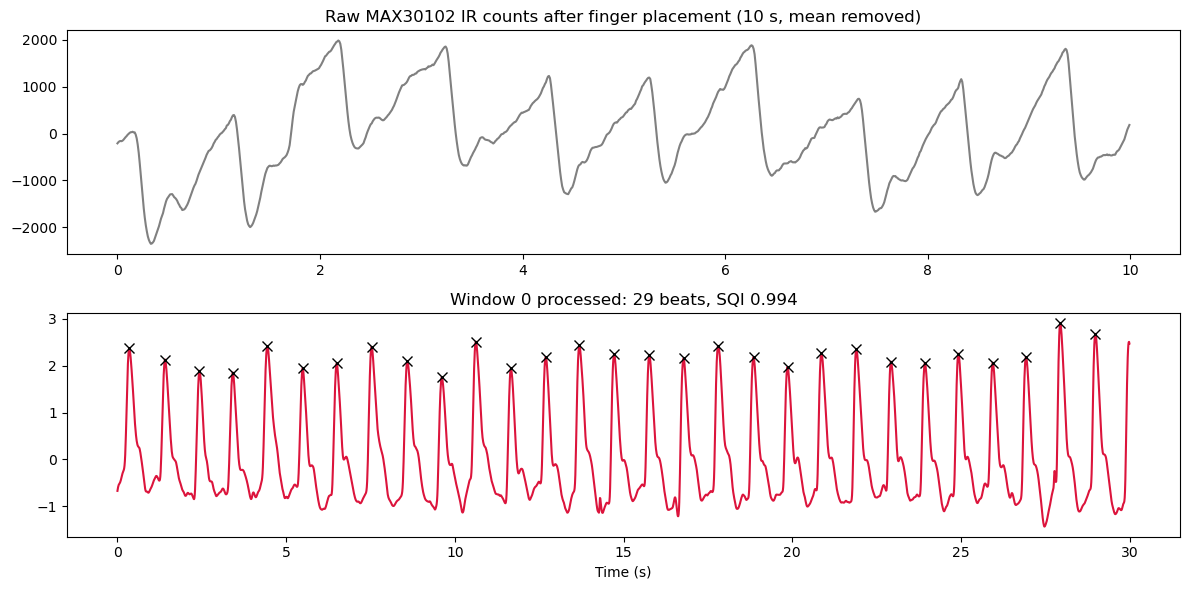

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from scipy.signal import butter, sosfilt, find_peaks

RECORDING = "data/recordings/rest_01.csv"
FS, WIN_SEC, SQI_THRESHOLD = 100, 30, 0.80

rec = pd.read_csv(RECORDING)

# ---- 1) Check the stream itself ----
duration = rec.host_time.iloc[-1] - rec.host_time.iloc[0]
gaps = int((rec.seq.diff().dropna() != 1).sum())
print(f"{len(rec)} samples over {duration:.1f} s -> {len(rec) / duration:.1f} Hz, "
      f"{gaps} gaps in sequence numbers")
print(f"IR raw counts: {rec.ir.min()} to {rec.ir.max()}"
      + ("  <-- SATURATED, lower LED_CURRENT" if rec.ir.max() >= 262143 else ""))

# ---- 2) Same processing as the MIMIC data, but no resampling (already 100 Hz) ----
def preprocess_device(ir):
    x = -np.asarray(ir, dtype=float)          # invert: MAX30102 counts dip on each pulse
    x = x - x[:FS].mean()                     # remove the large DC level (~100,000 counts)
    sos = butter(2, (0.5, 8.0), btype="bandpass", fs=FS, output="sos")
    return sosfilt(sos, x)                    # causal, same filter as training

def make_windows(x, skip_sec=2):
    win, skip = WIN_SEC * FS, skip_sec * FS
    out = []
    for i in range(skip, len(x) - win + 1, win):
        w = x[i:i + win]
        if w.std() > 1e-6:
            out.append((w - w.mean()) / w.std())
    return out

def detect_ppg_beats(w):
    return find_peaks(w, distance=int(0.33 * FS), prominence=0.5)[0]

def template_sqi(w):
    peaks = detect_ppg_beats(w)
    if len(peaks) < 5:
        return 0.0
    half = int(0.5 * np.median(np.diff(peaks)))
    beats = np.array([w[p - half:p + half] for p in peaks
                      if p - half >= 0 and p + half <= len(w)])
    if len(beats) < 5:
        return 0.0
    template = beats.mean(axis=0)
    return float(np.mean([np.corrcoef(b, template)[0, 1] for b in beats]))

def rhythm_features(w):
    peaks = detect_ppg_beats(w)
    if len(peaks) < 15:
        return None, None
    ibi = np.diff(peaks) / FS * 1000
    ibi = ibi[(ibi > 300) & (ibi < 2000)]
    if len(ibi) < 14:
        return None, None
    d = np.abs(np.diff(ibi))
    m = ibi.mean()
    feats = np.array([np.sqrt(np.mean(d ** 2)) / m, ibi.std() / m,
                      np.mean(d > 0.065 * m), np.median(d) / m], dtype=np.float32)
    return feats, 60000 / m

# ---- Start only once a finger is on the sensor and has settled ----
CONTACT_LEVEL = 50_000      # IR counts: well above "no finger" (~8,000), below "finger" (~130,000)
SETTLE_SEC = 3              # ignore the first seconds after placement (pressure settling)

ir_all = rec.ir.to_numpy()
on = ir_all > CONTACT_LEVEL
# first sample from which the finger stays on for at least 1 s
start = next((i for i in range(len(on) - FS) if on[i:i + FS].all()), None)
if start is None:
    raise ValueError("No finger contact found in this recording")
start += SETTLE_SEC * FS
print(f"Finger detected at {(start / FS) - SETTLE_SEC:.1f} s; analysis starts at {start / FS:.1f} s")
if (~on[start:]).any():
    print(f"  Warning: finger lifted for {(~on[start:]).sum() / FS:.1f} s during the recording")

clean = preprocess_device(ir_all[start:])
windows = make_windows(clean)

# ---- 3) Quality gate + int8 model on each 30 s window ----
interp = tf.lite.Interpreter(
    model_path="af_model.tflite",
    experimental_op_resolver_type=tf.lite.experimental.OpResolverType.BUILTIN_REF)
interp.allocate_tensors()
inp, out = interp.get_input_details()[0], interp.get_output_details()[0]
s_in, z_in = inp["quantization"]
s_out, z_out = out["quantization"]

print(f"\n{'window':>6} {'SQI':>6} {'HR':>6} {'nrmssd':>7} {'cv':>6} "
      f"{'pnn_rel':>7} {'mad_rel':>7} {'p(AF)':>6}  result")
for k, w in enumerate(windows):
    sqi = template_sqi(w)
    feats, hr = rhythm_features(w)
    if feats is None or sqi < SQI_THRESHOLD:
        print(f"{k:>6} {sqi:6.3f} {'':>6} {'':>7} {'':>6} {'':>7} {'':>7} {'':>6}  unreliable signal")
        continue
    q = np.clip(np.round(feats / s_in + z_in), -128, 127).astype(np.int8)
    interp.set_tensor(inp["index"], q[None, :])
    interp.invoke()
    o = int(interp.get_tensor(out["index"])[0, 0])
    p = (o - z_out) * s_out
    print(f"{k:>6} {sqi:6.3f} {hr:6.1f} {feats[0]:7.3f} {feats[1]:6.3f} "
          f"{feats[2]:7.3f} {feats[3]:7.3f} {p:6.3f}  {'possible AF' if o >= 0 else 'normal'}")

# ---- 4) Plot: raw pulse after finger placement, and the first processed window ----
fig, axes = plt.subplots(2, 1, figsize=(12, 6))
n = 10 * FS
seg = ir_all[start:start + n]
axes[0].plot(np.arange(len(seg)) / FS, seg - seg.mean(), color="gray")
axes[0].set_title("Raw MAX30102 IR counts after finger placement (10 s, mean removed)")
if windows:
    w = windows[0]
    pk = detect_ppg_beats(w)
    t = np.arange(len(w)) / FS
    axes[1].plot(t, w, color="crimson")
    axes[1].plot(t[pk], w[pk], "kx", ms=7)
    axes[1].set_title(f"Window 0 processed: {len(pk)} beats, SQI {template_sqi(w):.3f}")
axes[1].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()

## Step F3 results: live MAX30102 recording

Raw IR samples streamed from the MAX30102 over USB at **99.8 Hz with 0 lost samples** were processed with the same pipeline as the MIMIC data.

| | First attempts | Final recording |
|---|---|---|
| Pulse size | ~300–400 counts | ~3,000–4,000 counts |
| Beats detected (30 s) | 46–48 (false beats on noise) | 29 (every beat, no false beats) |
| SQI | 0.69–0.75 (rejected by gate) | **0.994** |

**What it took to get a clean signal:**
- **Wiring:** routing I2C through a shield and loose Grove connectors caused I2C errors and lost samples. Short direct wiring on a breadboard fixed it.
- **Ambient light:** room-light flicker added fast noise. A dark cover removed it.
- **Finger pressure:** pressing too hard pushes blood out of the fingertip and weakens the pulse about tenfold. A light, steady touch gave the strongest signal.

In the noisy recordings, the quality gate correctly rejected windows where noise produced false beats. Without the gate, those windows could have raised false AF alarms.  

- **LED brightness:** raising the LED current from 0x24 (~7.2 mA) to 0x30 (~9.6 mA) increased the IR level from ~134,000 to ~169,000 counts and strengthened the pulse, while staying well below saturation (262,143).
- **Finger placement:** a light, steady touch centred on the sensor window. Pressing hard pushes blood out of the fingertip and weakens the pulse.

| Window | SQI | Heart rate | nrmssd | cv | pnn_rel | mad_rel | p(AF) | Result |
|---|---|---|---|---|---|---|---|---|
| 0 | 0.994 | 58.7 | 0.027 | 0.019 | 0.000 | 0.029 | 0.000 | normal |
| 1 | 0.996 | 59.7 | 0.042 | 0.030 | 0.111 | 0.040 | 0.004 | normal |
| 2 | 0.993 | 60.3 | 0.045 | 0.041 | 0.107 | 0.035 | 0.004 | normal |

All windows pass the quality gate and are classified as normal rhythm, with features in the same range as the normal-rhythm patients in the MIMIC training data. A model trained on hospital monitor recordings gives correct, confident output on a low-cost MAX30102 sensor.

## Step F4: Full pipeline on the microcontroller

The complete pipeline (DC removal, band-pass filter, beat detection, quality gate, rhythm features and int8 model) is ported to C and runs on the nRF52840. Beat detection reproduces `scipy.signal.find_peaks` exactly: local maxima, then the minimum-distance rule, then the prominence rule, in the same order as scipy.

Two golden segments test it:
1. **Your own MAX30102 recording** (normal rhythm), from after finger placement.
2. **A real AF patient from MIMIC**, resampled to 100 Hz and converted to MAX30102-like raw counts. This tests the whole device pipeline on real AF without needing a person with AF.

The board streams each segment sample by sample through the same code the live sensor uses, and every 30 s window must match Python's beat count, SQI, features, quality-gate decision and model output.

In [41]:
import glob
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf
from scipy.signal import butter, sosfilt, find_peaks, resample_poly

RECORDING = "data/recordings/rest_01.csv"
FW_SRC = Path("C:/Zephyr/zephyrproject/AF_Project/af_pipeline/src")
FS, WIN_SEC = 100, 30
SEG_LEN = 2 * FS + 3 * WIN_SEC * FS        # 2 s settling + three 30 s windows = 9,200 samples

# ---- Python reference pipeline (identical to the F3 cell) ----
def preprocess_device(ir):
    x = -np.asarray(ir, dtype=float)
    x = x - x[:FS].mean()
    sos = butter(2, (0.5, 8.0), btype="bandpass", fs=FS, output="sos")
    return sosfilt(sos, x)

def make_windows(x, skip_sec=2):
    win, skip = WIN_SEC * FS, skip_sec * FS
    return [(x[i:i + win] - x[i:i + win].mean()) / x[i:i + win].std()
            for i in range(skip, len(x) - win + 1, win)]

def detect_ppg_beats(w):
    return find_peaks(w, distance=int(0.33 * FS), prominence=0.5)[0]

def template_sqi(w):
    peaks = detect_ppg_beats(w)
    if len(peaks) < 5:
        return 0.0
    half = int(0.5 * np.median(np.diff(peaks)))
    beats = np.array([w[p - half:p + half] for p in peaks if p - half >= 0 and p + half <= len(w)])
    if len(beats) < 5:
        return 0.0
    template = beats.mean(axis=0)
    return float(np.mean([np.corrcoef(b, template)[0, 1] for b in beats]))

def rhythm_features(w):
    peaks = detect_ppg_beats(w)
    if len(peaks) < 15:
        return None, None
    ibi = np.diff(peaks) / FS * 1000
    ibi = ibi[(ibi > 300) & (ibi < 2000)]
    if len(ibi) < 14:
        return None, None
    d = np.abs(np.diff(ibi))
    m = ibi.mean()
    return np.array([np.sqrt(np.mean(d ** 2)) / m, ibi.std() / m,
                     np.mean(d > 0.065 * m), np.median(d) / m], dtype=np.float32), 60000 / m

interp = tf.lite.Interpreter(
    model_path="af_model.tflite",
    experimental_op_resolver_type=tf.lite.experimental.OpResolverType.BUILTIN_REF)
interp.allocate_tensors()
inp, out = interp.get_input_details()[0], interp.get_output_details()[0]
s_in, z_in = inp["quantization"]

def run_model(feats):
    q = np.clip(np.round(feats / s_in + z_in), -128, 127).astype(np.int8)
    interp.set_tensor(inp["index"], q[None, :])
    interp.invoke()
    return int(interp.get_tensor(out["index"])[0, 0])

def analyse_segment(raw):
    rows = []
    for w in make_windows(preprocess_device(raw)):
        sqi = template_sqi(w)
        feats, hr = rhythm_features(w)
        valid = feats is not None
        rows.append(dict(n_beats=len(detect_ppg_beats(w)), sqi=sqi, valid=valid,
                         feats=feats if valid else np.zeros(4), hr=hr if valid else 0.0,
                         gate=valid and sqi >= 0.80,
                         model=run_model(feats) if valid else -128))
    return rows

def result_name(r):
    return "unreliable" if not r["gate"] else ("possible AF" if r["model"] >= 0 else "normal")

# ---- Segment 1: your own MAX30102 recording, from after finger placement ----
rec = pd.read_csv(RECORDING)
ir_all = rec.ir.to_numpy()
on = ir_all > 50_000
start = next(i for i in range(len(on) - FS) if on[i:i + FS].all()) + 3 * FS
seg_own = ir_all[start:start + SEG_LEN].astype(np.int32)
assert len(seg_own) == SEG_LEN, "recording too short: need ~95 s after finger placement"

# ---- Segment 2: a real AF patient from MIMIC, converted to MAX30102-like counts ----
def to_device_counts(ppg):
    scale = 3000 / (np.percentile(ppg, 95) - np.percentile(ppg, 5))
    return np.round(134000 - scale * (ppg - ppg.mean())).astype(np.int32)

af_files = sorted(glob.glob("data/raw/af/**/*.csv", recursive=True))
seg_af, af_name = None, None
for f in af_files:
    ppg = pd.read_csv(f, usecols=["PPG"])["PPG"].interpolate(limit=10).to_numpy()
    ppg = resample_poly(ppg, 100, 125)
    for t0 in range(60 * FS, len(ppg) - SEG_LEN, 120 * FS):
        part = ppg[t0:t0 + SEG_LEN]
        if np.isnan(part).any():
            continue
        candidate = to_device_counts(part)
        rows = analyse_segment(candidate)
        if sum(r["gate"] and r["model"] >= 0 for r in rows) >= 2:   # clear AF example
            seg_af, af_name = candidate, f"MIMIC {Path(f).stem.replace('_data', '')} at {t0 // FS} s"
            break
    if seg_af is not None:
        break
assert seg_af is not None, "no AF segment found"

segments = [("Your MAX30102 recording", seg_own, 0), (af_name, seg_af, 1)]

# ---- Write golden_dsp.h ----
lines = ["// Golden test data for the on-device pipeline (generated by the notebook)",
         "#pragma once", "#include <stdint.h>", "",
         f"#define GOLDEN_NUM_SEGMENTS {len(segments)}",
         f"#define GOLDEN_SEG_LEN {SEG_LEN}",
         "#define GOLDEN_WINDOWS_PER_SEG 3", "",
         "struct golden_window {",
         "\tint16_t n_beats;", "\tfloat sqi;", "\tuint8_t valid;", "\tfloat features[4];",
         "\tfloat hr;", "\tuint8_t gate;", "\tint8_t model_out;", "};", "",
         "static const char *const golden_seg_name[GOLDEN_NUM_SEGMENTS] = {"
         + ", ".join(f'"{n}"' for n, _, _ in segments) + "};",
         "static const uint8_t golden_seg_label[GOLDEN_NUM_SEGMENTS] = {"
         + ", ".join(str(l) for _, _, l in segments) + "};   /* 0 normal, 1 AF */", "",
         "static const int32_t golden_raw[GOLDEN_NUM_SEGMENTS][GOLDEN_SEG_LEN] = {"]
for _, raw, _ in segments:
    lines.append("\t{")
    for i in range(0, SEG_LEN, 16):
        lines.append("\t\t" + ", ".join(str(int(v)) for v in raw[i:i + 16]) + ",")
    lines.append("\t},")
lines += ["};", "",
          "static const struct golden_window golden_expected[GOLDEN_NUM_SEGMENTS][GOLDEN_WINDOWS_PER_SEG] = {"]

print(f"{'segment':42s} {'win':>3} {'beats':>5} {'SQI':>6} {'HR':>6} {'model':>5}  result")
for name, raw, _ in segments:
    rows = analyse_segment(raw)
    lines.append("\t{")
    for k, r in enumerate(rows):
        f = ", ".join(f"{v:.8f}f" for v in r["feats"])
        lines.append(f"\t\t{{ {r['n_beats']}, {r['sqi']:.8f}f, {int(r['valid'])}, {{ {f} }}, "
                     f"{r['hr']:.6f}f, {int(r['gate'])}, {r['model']} }},")
        print(f"{name:42s} {k:>3} {r['n_beats']:>5} {r['sqi']:6.3f} {r['hr']:6.1f} "
              f"{r['model']:>5}  {result_name(r)}")
    lines.append("\t},")
lines.append("};")

FW_SRC.mkdir(parents=True, exist_ok=True)
(FW_SRC / "golden_dsp.h").write_text("\n".join(lines) + "\n")
print(f"\nWrote {FW_SRC / 'golden_dsp.h'}")

segment                                    win beats    SQI     HR model  result
Your MAX30102 recording                      0    29  0.994   58.7  -128  normal
Your MAX30102 recording                      1    29  0.996   59.7  -127  normal
Your MAX30102 recording                      2    30  0.993   60.3  -127  normal
MIMIC mimic_perform_af_001 at 60 s           0    45  0.957   91.1   127  possible AF
MIMIC mimic_perform_af_001 at 60 s           1    46  0.925   93.3   125  possible AF
MIMIC mimic_perform_af_001 at 60 s           2    46  0.976   92.0   127  possible AF

Wrote C:\Zephyr\zephyrproject\AF_Project\af_pipeline\src\golden_dsp.h


### Step F4 results: full pipeline on the nRF52840

| Segment | Window | Beats | SQI | HR (bpm) | Model output | Board result | Matches Python |
|---|---|---|---|---|---|---|---|
| Own MAX30102 recording (normal) | 0 | 29 | 0.994 | 58.7 | −128 | normal | yes |
| | 1 | 29 | 0.996 | 59.7 | −127 | normal | yes |
| | 2 | 30 | 0.993 | 60.3 | −127 | normal | yes |
| MIMIC AF patient 001 (AF) | 0 | 45 | 0.957 | 91.1 | 127 | possible AF | yes |
| | 1 | 46 | 0.925 | 93.3 | 125 | possible AF | yes |
| | 2 | 46 | 0.976 | 92.0 | 127 | possible AF | yes |

- All 6 windows match the Python reference (beat count, quality gate, model output); largest differences: SQI 4.2 × 10⁻⁷, features 3.0 × 10⁻⁸.
- **11.9 ms** to analyse one 30 s window (DSP + int8 model) on a 64 MHz Cortex-M4F, about 0.04% CPU duty cycle.
- Before porting, the C implementation was checked against Python on 120 synthetic windows (normal, AF, ectopic beats, heavy noise, weak signal) with zero mismatches.

## Live test results

The full pipeline running on the Arduino Nano 33 BLE Sense with a live MAX30102 sensor, tested on one healthy subject. The finger was placed and lifted between windows, so each session gave one 30 s window.

| Session | Window | Result | HR (bpm) | SQI | Beats | p(AF) | Processing time |
|---|---|---|---|---|---|---|---|
| 1 | 0 | normal | 85 | 0.90 | – | 0.02 | 12.1 ms |
| 2 | 0 | normal | 74 | 0.90 | – | 0.05 | 11.7 ms |
| 3 | 0 | unreliable signal | – | 0.62 | 40 | – | – |
| 4 | 0 | normal | 79 | 0.82 | – | 0.02 | 11.9 ms |
| 5 | 0 | unreliable signal | – | 0.67 | 42 | – | – |
| 6 | 0 | unreliable signal | – | 0.76 | 40 | – | – |
| 7 | 0 | **normal** | **65** | **0.98** | – | **0.00** | 10.5 ms |

**Summary:** 7 windows, 4 normal, 3 rejected as unreliable, **0 false AF alarms**.

**Observations:**
- **Session 3 lost data:** 3,001 samples (about 30 s) were lost to I²C errors while the finger was repeatedly placed and lifted, which flexed the sensor wiring. The gate rejected the window (SQI 0.62). The firmware was then changed to discard and restart any measurement in which a sample is lost, so a result is never computed from incomplete data. Sessions 4–7 ran with this change and lost no samples.
- **Signal quality varied between finger placements** (SQI 0.62–0.98). The cleanest window (SQI 0.98) gave 65 bpm, consistent with earlier resting recordings (58.7–60.3 bpm). Lower-quality windows gave higher heart rates (74–85 bpm) or about 40 beats per 30 s, which suggests the beat detector over-counts secondary pulse peaks when the signal is weaker. This was not checked against a manual pulse count.
- **The gate kept the rhythm decision safe but not always the heart rate:** windows at SQI 0.82–0.90 passed with a correct "normal" rhythm call but a possibly inflated heart rate. A stricter threshold may be needed when heart rate is reported.
- Continuous multi-window recordings (finger kept on the sensor) are still to be done.